# ATO1 Marche Nord — Extended Forecasting Pipeline
## Hydroclimatic, Seismic, and Socioeconomic Drivers of Civil Water Demand and Network Losses

**Scope of this notebook.** This is a self-contained extension of the corrected
LSTM/Transformer pipeline (the minimal pipeline (`ATO1_minimal_pipeline.ipynb`)), implementing the
additional variables and analyses recommended in the accompanying review
document (`additional_variables_and_improvements.md`). It runs end-to-end from
**data acquisition** (hydroclimatic data via Google Earth Engine, tourism data
via ISTAT, seismic event variables computed directly) through **feature
engineering**, **exploratory analysis**, **modelling** (baselines, LSTM,
Transformer, CNN-LSTM, XGBoost), **rolling-origin backtesting**, and
**interpretability** (ablation, SHAP, uncertainty quantification).

**What's reused vs. new.** The leakage-free preprocessing and rolling-origin
backtest framework are carried over from the minimal pipeline (`ATO1_minimal_pipeline.ipynb`)
(condensed here for self-containment) since that machinery is already
validated. Everything in Sections 2-4 (data acquisition, integration, EDA) and
the new model families in Sections 8-9 (CNN-LSTM, XGBoost) and Sections 12-14
(ablation, SHAP, uncertainty) is new.

**Environment note.** This notebook was authored and syntax-checked in an
environment without network access, TensorFlow, statsmodels, xgboost, shap,
or the Earth Engine API. Every code cell was verified to parse correctly
(`compile()`), and the pure pandas/NumPy/scikit-learn logic (rolling-origin
windowing, leakage checks, the seismic decay formula, the manual SPI/SPEI
implementation) was empirically tested against synthetic data shaped like
your real dataset. The deep-learning, SARIMA, GEE, and SHAP cells will run in
your local conda environment (`neural311`) where those packages are already
installed, but have not been execution-tested end-to-end here — review the
first run's output carefully, the same way you did for the previous two
pipeline versions.

**A note on the dataset's fundamental size constraint.** N=60 months is small
for 12-step-ahead deep learning under any methodology. Every fix in this
notebook (rolling-origin evaluation, additional covariates) improves the
*validity* and *informativeness* of the analysis, but cannot manufacture
statistical power that 60 monthly observations don't contain. Some of the
richer models below (TFT-style architectures, full SHAP attribution) are
included because they are scientifically appropriate to discuss and attempt,
not because N=60 guarantees they will outperform the baselines — that
comparison itself is part of the contribution.

## 0. RUNME setup — self-contained extended (14-feature) re-run

This is a **runnable, self-contained** version of the Part 2 *extended* pipeline (Config A = 14 features: 4 operational drivers + 3 calendar terms + SPI-3 / SPEI-3 / precipitation-anomaly / temperature + tourist-equivalent population + 2 seismic terms). It runs **fully offline** from `./data_cache/` (ERA5-Land, the 1991-2020 climatology, and ISTAT tourism are already cached there) — **no Earth Engine or internet is required**. Relative to the archived Part 2 notebook it changes only four things, all flagged `[RUNME]`: (1) installs `xgboost` if missing; (2) adds a SARIMA magnitude guard; (3) sets **N_SEEDS = 5** (switchable to 3); (4) writes `output_part2_5seed/configa_extended_predictions_long.csv`. Requires `tensorflow`, `statsmodels`, `scikit-learn`, `openpyxl` in the active environment (your `neural311`-style env). Expect **~2-3 h** on a laptop CPU at 5 seeds (the long-horizon models retrain at every rolling origin); set `N_SEEDS = 3` to roughly halve it.

In [ ]:
# Paths in this notebook are relative to the repository root (data/, data_cache/, output_*/).
# If Jupyter or VS Code starts the kernel inside notebooks/, move up to the repository root.
import os
from pathlib import Path
if not Path('data_cache').exists() and Path('../data_cache').exists():
    os.chdir('..')
print('Working directory: repository root' if Path('data_cache').exists() else 'Warning: data_cache/ not found - start Jupyter in the repository or notebooks/ folder')

In [1]:
# === [RUNME] SETUP =========================================================
import sys, subprocess, importlib.util
# xgboost was the one dependency silently missing in an earlier run (its
# absence turned every XGBoost NSE into NaN). Ensure it is installed.
if importlib.util.find_spec('xgboost') is None:
    print('Installing xgboost ...')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'xgboost'])
# tensorflow + statsmodels are required and heavy — they should already be in
# your env. We only CHECK for them here; we do not pip-install them for you.
_missing = [m for m in ('tensorflow', 'statsmodels', 'sklearn', 'openpyxl')
            if importlib.util.find_spec(m) is None]
if _missing:
    print('WARNING — missing required packages:', _missing,
          '\n  install them before running the rest:'
          '\n  pip install tensorflow statsmodels scikit-learn openpyxl')
else:
    print('All required packages present. Extended pipeline will run offline from data_cache/.')


All required packages present. Extended pipeline will run offline from data_cache/.


## 1. Environment & Dependencies

New packages used in this notebook beyond the original pipeline:

| Package | Purpose | Install |
|---|---|---|
| `earthengine-api` | ERA5-Land precipitation/temperature/PET extraction | `pip install earthengine-api` |
| `xgboost` | Gradient-boosted tabular baseline | `pip install xgboost` |
| `shap` | Feature attribution for the best model | `pip install shap` |

SPI/SPEI are implemented manually with `scipy.stats` in Section 4.4 (no extra
package required) for full transparency and auditability — the same framing
your abstract already uses for the modelling pipeline itself. If you'd rather
use a maintained package, `pip install spei` (martinvonk/SPEI, pandas-native,
also computes a Standardized Groundwater Index — directly relevant to
Sorgenti/Pozzi) or `pip install climate-indices` (NOAA/NCEI reference
implementation, grid-oriented) are both reasonable alternatives; Section 4.4
notes where they'd slot in.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
from itertools import product
from datetime import datetime

from scipy import stats
from scipy.special import gamma as sp_gamma   # the Gamma FUNCTION (Γ), for Section 4.4's PWM log-logistic fit -- distinct from scipy.stats.gamma, the Gamma DISTRIBUTION
import math   # math.comb, for the same PWM fit's binomial-coefficient weights
from scipy.stats import t as t_dist
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error

np.random.seed(42)

DATA_PATH  = Path('data/Dataset.xlsx')          # adjust to your actual path
CACHE_DIR  = Path('data_cache')                  # downloaded/exported external data lands here
OUTPUT_DIR = Path('output_part2_5seed')  # [RUNME] fresh folder; keeps the reference output_part2/ intact
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

features_base = ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori']
targets = ['Fabbisogni', 'Perdite']
N_TARGETS = len(targets)

print("Environment ready. Cache ->", CACHE_DIR.resolve(), "| Output ->", OUTPUT_DIR.resolve())

Environment ready. Cache -> <repo>\data_cache | Output -> <repo>\output_part2_5seed


## 2. Data Acquisition

Five sources are combined in this section:

1. **2.1** — your existing ATO1 operational dataset (`Dataset.xlsx`)
2. **2.2** — hydroclimatic data (precipitation, temperature, potential
   evapotranspiration) from **ERA5-Land Monthly Aggregated** via Google Earth
   Engine — chosen for consistency with the ERA5-LAND/GEE methodology you
   already use in your BVOC emissions pipeline
3. **2.3** — a manual Hargreaves-Samani PET cross-check, computed independently
   of ERA5's own PET band, since ERA5's `potential_evaporation_sum` is
   documented to give unrealistic results in some conditions and a second,
   fully-transparent estimate is good practice for an auditable pipeline
4. **2.4** — a tourism proxy from ISTAT's "Movimento dei clienti negli esercizi
   ricettivi" survey (monthly arrivals/overnight stays by province)
5. **2.5** — seismic phase/decay variables computed directly from known
   earthquake dates (no external download needed)

### 2.1 Load the ATO1 operational dataset

In [3]:
def load_ato1_data(path: Path) -> pd.DataFrame:
    df = pd.read_excel(path)
    date_col = 'Data' if 'Data' in df.columns else df.columns[0]
    df = df.rename(columns={date_col: 'date'}).set_index('date')
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    print(f"Loaded {len(df)} monthly records: {df.index[0]:%Y-%m} -> {df.index[-1]:%Y-%m}")
    assert len(df) >= 30, "Dataset too short for reliable deep-learning experiments."
    return df

df = load_ato1_data(DATA_PATH)
df[features_base + targets].describe().round(1)

Loaded 60 monthly records: 2017-01 -> 2021-12


[Output removed for the public release: this cell displays rows or summary statistics of the operator-supplied monthly series (MMS / ASET), which are withheld under the providers' data-sharing conditions. See data/README_DATA.md.]


### 2.2 Hydroclimatic data — ERA5-Land Monthly Aggregated via Google Earth Engine

**Source:** `ECMWF/ERA5_LAND/MONTHLY_AGGR` (verified collection ID, available
1950-02 to near-real-time, ~11.1 km pixel resolution). Bands used:

| Band | Units | Meaning |
|---|---|---|
| `temperature_2m` | K | monthly-mean 2m air temperature |
| `total_precipitation_sum` | m | monthly accumulated precipitation (flow band) |
| `potential_evaporation_sum` | m | monthly accumulated potential evaporation |

**Known caveats (from the official Earth Engine catalog entry and ECMWF's
own documentation, worth keeping in mind when you interpret results):**
precipitation and other accumulated ("flow") bands can occasionally show
small negative values due to GRIB packing artifacts — clip at zero
downstream. `potential_evaporation_sum` can give unrealistic results in
arid conditions per ECMWF's own documentation, which is exactly why
Section 2.3 computes an independent Hargreaves estimate as a cross-check
rather than trusting either PET source alone.

**Sign convention (this matters and is easy to get wrong).** ECMWF's IFS
convention is that *downward* fluxes are positive: a quantity leaving the
surface (evaporation) is therefore stored as a **negative** number, and a
quantity arriving at the surface (condensation, or precipitation) is
positive (ECMWF Confluence, "ERA5-Land Evapotranspiration":
*"the ECMWF Integrated Forecasting System convention is that downward
fluxes are positive. Therefore, negative values indicate evaporation and
positive values indicate condensation."*). Concretely, for almost any real
land surface in almost any month, `potential_evaporation_sum` will be
**negative**. The fix below negates it before converting units, so that
"more potential evaporation" reads as a larger positive `pet_era5_mm`,
matching the convention every PET equation in the hydrology literature
(including the Hargreaves formula in Section 2.3) already assumes.

**Bounding box.** The placeholder box below covers the Province of
Pesaro-Urbino at a coarse level. **Replace this with your actual catchment
boundary** (you likely already have shapefiles for the springs/wells supply
basins from prior hydrogeological studies, or the WRF domain shapefile from
your other pipeline) before running this for real — ERA5-Land's ~11 km pixels
mean the exact box matters for anything but a province-wide average.

In [4]:
# --- Run this cell in an environment with internet access and Earth Engine
# credentials (this sandbox has neither). Authenticate once per machine with
# ee.Authenticate(), which opens a browser OAuth flow; ee.Initialize() after
# that reuses the cached token.

ERA5_CACHE = CACHE_DIR / 'era5_land_monthly.csv'

def fetch_era5_land_gee(start_date: str, end_date: str,
                         bbox=(12.179, 43.415, 13.175, 43.978),
                         cache_path: Path = ERA5_CACHE,
                         gee_project: str = None) -> pd.DataFrame:
    '''
    bbox = (lon_min, lat_min, lon_max, lat_max). Default is the refined ATO1
    catchment box; replace with your exact catchment geometry if you have a
    shapefile (e.g. from prior hydrogeological delineation or the WRF domain
    used in your other pipeline) for a tighter spatial match.

    gee_project: as of Google's 2024 Earth Engine policy change, EVERY
    ee.Initialize() call must be associated with a Cloud project (a legacy
    no-project Initialize() will raise an authentication error). Pass your
    project ID here, e.g. gee_project='ee-yourusername'.

    Returns a monthly DataFrame indexed by date with columns:
        precip_mm, temp_C, pet_era5_mm
    Caches to CSV so this only needs to run once per date range.
    '''
    if cache_path.exists():
        print(f"Loading cached ERA5-Land extraction: {cache_path}")
        cached = pd.read_csv(cache_path, index_col=0, parse_dates=True)
        # [DEFENSIVE CHECK] A cache written before the PET sign-convention
        # fix below would have pet_era5_mm == 0 for every single month
        # (std == 0) -- that's not a plausible physical result anywhere, so
        # treat it as a stale cache and force a re-fetch rather than
        # silently propagating a known-wrong value.
        if 'pet_era5_mm' in cached.columns and cached['pet_era5_mm'].std() == 0:
            print("  WARNING: cached pet_era5_mm has zero variance (all-zero) -- "
                  "this is the signature of the pre-fix sign-convention bug, not a "
                  "real result. Deleting the stale cache and re-fetching.")
            cache_path.unlink()
        else:
            return cached

    try:
        import ee
        ee.Authenticate()          # one-time browser OAuth; cached afterwards
        ee.Initialize(project=gee_project)
    except Exception as e:
        print(f"Earth Engine not available here ({e}). "
              f"Run this cell in your local environment with `earthengine-api` "
              f"installed, a registered GEE Cloud project passed as `gee_project`, "
              f"or load a previously exported CSV into {cache_path}.")
        return pd.DataFrame()

    # [DEFENSIVE CHECK] A single stray comma where a decimal point was meant
    # (e.g. `43,978` instead of `43.978`) silently turns this 4-element bbox
    # into a 5-element tuple in Python -- which would raise a confusing
    # "too many values to unpack" error here, and ONLY on a cache miss,
    # since the cache short-circuit above returns before this line runs.
    # That combination (latent bug, only triggers on a code path you might
    # not exercise for weeks) is exactly the kind of bug worth catching
    # explicitly and immediately instead of leaving it for `lon_min, lat_min,
    # lon_max, lat_max = bbox` to fail on its own, less clearly.
    assert len(bbox) == 4, (
        f"bbox must have exactly 4 elements (lon_min, lat_min, lon_max, lat_max), "
        f"got {len(bbox)}: {bbox}. If you just edited this value, check for a "
        f"comma where a decimal point was meant (e.g. '43,978' instead of '43.978').")
    lon_min, lat_min, lon_max, lat_max = bbox
    region = ee.Geometry.Rectangle([lon_min, lat_min, lon_max, lat_max])

    coll = (ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')
              .filterDate(start_date, end_date)
              .select(['temperature_2m', 'total_precipitation_sum', 'potential_evaporation_sum']))

    def reduce_image(img):
        stats = img.reduceRegion(reducer=ee.Reducer.mean(), geometry=region, scale=11132)
        return ee.Feature(None, stats.set('date', img.date().format('YYYY-MM-dd')))

    fc = coll.map(reduce_image)
    records = fc.getInfo()['features']

    rows = []
    for r in records:
        p = r['properties']
        # [FIX] potential_evaporation_sum follows ECMWF's downward-positive
        # flux convention, so genuine evaporation is NEGATIVE (see Section
        # 2.2 markdown for the cited explanation). Negate FIRST, then clip
        # at zero -- clipping is still appropriate after the sign flip, to
        # catch the rare condensation-dominated month (now negative) the
        # same way precipitation's GRIB noise is clipped.
        rows.append({
            'date': p.get('date'),
            'temp_C': p.get('temperature_2m', np.nan) - 273.15,           # K -> C
            'precip_mm': max(p.get('total_precipitation_sum', np.nan) * 1000, 0),  # m -> mm, clip GRIB artifacts
            'pet_era5_mm': max(-p.get('potential_evaporation_sum', np.nan) * 1000, 0),  # m -> mm, SIGN-FLIPPED, then clip
        })
    era5_df = pd.DataFrame(rows).set_index('date')
    era5_df.index = pd.to_datetime(era5_df.index)
    era5_df.to_csv(cache_path)
    print(f"Fetched and cached {len(era5_df)} months of ERA5-Land data -> {cache_path}")
    return era5_df

era5_df = fetch_era5_land_gee(start_date=f'{df.index[0]:%Y-%m-%d}',
                               end_date=f'{(df.index[-1] + pd.DateOffset(months=1)):%Y-%m-%d}',
                               bbox=(12.179, 43.415, 13.175, 43.978),   # ATO1 catchment bounding box
                               gee_project='ee-yourusername')
if era5_df.empty:
    print("\nNo ERA5 data available in this session -- downstream cells that "
          "depend on precip_mm/temp_C will be skipped gracefully (see Section 3).")
else:
    era5_df.head()

Loading cached ERA5-Land extraction: data_cache\era5_land_monthly.csv


### 2.2b Long-period climatology fetch (for SPI/SPEI calibration in Section 4.4)

**This subsection exists because of a real bug found in an actual run of
this notebook, and is worth understanding even before reaching Section 4.4.**
SPI/SPEI work by fitting a probability distribution to precipitation (or
water balance) *per calendar month*, then scoring each month's value against
that fitted distribution. Fitting that distribution from only the 2017-2021
study period itself means each calendar month gets just 5 data points to fit
a 2-3 parameter distribution from -- and combined with the 2-3 month startup
NaN every rolling-sum accumulation has, some calendar months (January and
February, in the actual run that surfaced this) ended up with only 4 valid
years, just under whatever minimum-sample threshold the fit requires. The
practical consequence in that run: SPI/SPEI were NaN for those calendar
months in EVERY year, which then poisoned every LSTM/Transformer/CNN-LSTM
training window touching a January or February timestep -- visible in the
real output as nearly-identical, severely negative NSE across all three
neural architectures (XGBoost was unaffected, since it has native
missing-value handling; Keras/TensorFlow do not, and silently propagate NaN
through every subsequent weight update).

The standard fix is also the textbook-correct one: the WMO's own SPI User
Guide states a minimum of 20-30 years of data is recommended for fitting,
with 50-60+ years preferred (Svoboda, Hayes & Wood, 2012, *Standardized
Precipitation Index User Guide*, WMO-No. 1090); some operational centers
simply don't compute SPI at all below a 30-year record. ERA5-Land is
available from 1950, so there's no reason to settle for 5 years here. This
cell fetches the WMO-style 30-year climate-normal period (1991-2020) for the
*same* bounding box, used **only** to fit SPI/SPEI's distribution parameters
in Section 4.4 -- the actual index VALUES reported are still for your
2017-2021 months of interest, just scored against a properly-sized
climatology instead of against themselves.

In [5]:
ERA5_CLIMATOLOGY_CACHE = CACHE_DIR / 'era5_land_climatology_1991_2020.csv'

era5_climatology_df = fetch_era5_land_gee(
    start_date='1991-01-01', end_date='2021-01-01',
    bbox=(12.179, 43.415, 13.175, 43.978),
    cache_path=ERA5_CLIMATOLOGY_CACHE,
    gee_project='ee-yourusername')

if era5_climatology_df.empty:
    print("No climatology data available this session -- Section 4.4's SPI/SPEI "
          "will fall back to the short study-period-only calibration (with the "
          "associated NaN risk for thinly-sampled calendar months) and print a "
          "warning explaining the consequence when that happens.")
else:
    print(f"Climatology reference period: {len(era5_climatology_df)} months "
         f"({era5_climatology_df.index[0]:%Y-%m} -> {era5_climatology_df.index[-1]:%Y-%m})")
    print(era5_climatology_df.groupby(era5_climatology_df.index.month).size()
         .rename('years_available_per_calendar_month').to_string())

Loading cached ERA5-Land extraction: data_cache\era5_land_climatology_1991_2020.csv
Climatology reference period: 360 months (1991-01 -> 2020-12)
date
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30


### 2.3 Potential evapotranspiration cross-check — manual Hargreaves-Samani

Computed independently of ERA5's own PET band as a transparency cross-check.
Requires only T_max, T_min (here approximated from monthly mean ± a typical
diurnal range, since only monthly-mean temperature is pulled from ERA5-Land
above — replace with true monthly T_max/T_min if you extract them) and
extraterrestrial radiation Ra, computed analytically from latitude and
day-of-year (FAO-56, Allen et al., 1998).

In [6]:
LATITUDE_DEG = 43.90   # Pesaro-Urbino approx. -- replace with your catchment centroid

def extraterrestrial_radiation(lat_deg: float, doy: int) -> float:
    '''
    Ra in MJ m-2 day-1, FAO-56 Penman-Monteith framework (Allen et al., 1998,
    FAO Irrigation and Drainage Paper 56, eq. 21).
    '''
    lat = np.radians(lat_deg)
    dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365)                       # inverse rel. Earth-Sun distance
    delta = 0.409 * np.sin(2 * np.pi * doy / 365 - 1.39)                  # solar declination
    ws = np.arccos(np.clip(-np.tan(lat) * np.tan(delta), -1, 1))          # sunset hour angle
    Ra = (24 * 60 / np.pi) * 0.0820 * dr * (
        ws * np.sin(lat) * np.sin(delta) + np.cos(lat) * np.cos(delta) * np.sin(ws)
    )
    return Ra   # MJ m-2 day-1


def hargreaves_pet(t_mean_C: pd.Series, diurnal_range_C: float = 9.0,
                   lat_deg: float = LATITUDE_DEG) -> pd.Series:
    '''
    Hargreaves & Samani (1985): PET = 0.0023 * Ra * (Tmean+17.8) * sqrt(Tmax-Tmin)
    Returns mm/month (Ra converted from MJ m-2 day-1 to mm/day via /2.45,
    then multiplied by days in month).

    `diurnal_range_C` is a placeholder typical value when only monthly-mean
    temperature is available; replace with actual monthly (Tmax-Tmin) once
    you extract `temperature_2m_max` / `temperature_2m_min` bands from
    ERA5-Land in Section 2.2 for a materially better estimate.
    '''
    doy = t_mean_C.index.dayofyear
    Ra_mj = np.array([extraterrestrial_radiation(lat_deg, d) for d in doy])
    Ra_mm_day = Ra_mj / 2.45                       # MJ m-2 day-1 -> mm/day (latent heat of vaporization)
    pet_mm_day = 0.0023 * Ra_mm_day * (t_mean_C.values + 17.8) * np.sqrt(diurnal_range_C)
    days_in_month = t_mean_C.index.days_in_month
    return pd.Series(pet_mm_day * days_in_month, index=t_mean_C.index, name='pet_hargreaves_mm')


if not era5_df.empty:
    pet_hg = hargreaves_pet(era5_df['temp_C'])
    cross_check = pd.concat([era5_df['pet_era5_mm'], pet_hg], axis=1)
    print(cross_check.describe().round(1))
    if era5_df['pet_era5_mm'].std() == 0:
        # [DEFENSIVE CHECK] A constant pet_era5_mm makes the correlation
        # below mathematically undefined (0/0 -> NaN), and is itself the
        # diagnostic that matters: it means Section 2.2's GEE extraction
        # returned no real variation (most likely a stale pre-fix cache --
        # Section 2.2's loader now detects and clears that automatically,
        # but flag it loudly here too in case this cell is ever run in
        # isolation against an externally-supplied era5_df).
        print("\nWARNING: pet_era5_mm has zero variance -- correlation with "
              "the Hargreaves estimate is undefined. This points to an upstream "
              "extraction problem (see Section 2.2), not a real cross-check result.")
    else:
        corr = cross_check.corr().iloc[0, 1]
        print(f"\nCorrelation between ERA5 PET and manual Hargreaves PET: {corr:.3f}")
        print("Large divergence would flag a real ERA5 PET issue (the 'unrealistic "
              "in arid conditions' caveat from Section 2.2) worth investigating "
              "before trusting either series as a model input.")
else:
    print("Skipping PET cross-check -- no ERA5 data available in this session.")

       pet_era5_mm  pet_hargreaves_mm
count         60.0               60.0
mean         143.7               78.0
std           84.8               46.0
min           32.8               19.3
25%           58.1               35.5
50%          145.0               69.4
75%          227.7              116.2
max          308.9              152.2

Correlation between ERA5 PET and manual Hargreaves PET: 0.963
Large divergence would flag a real ERA5 PET issue (the 'unrealistic in arid conditions' caveat from Section 2.2) worth investigating before trusting either series as a model input.


### 2.4 Tourism proxy — ISTAT "Movimento dei clienti negli esercizi ricettivi"

**Source:** Istat's official tourism survey, browsable at `dati.istat.it`
(I.Stat data warehouse). It reports monthly arrivals and overnight stays by
municipality/province/type of accommodation, available from 2017 onward —
exactly your study period.

**There is no single stable public API endpoint we can hard-code reliably**
(I.Stat's SDMX interface exists but its exact query parameters vary by table
revision), so the practical, honest approach is a one-time manual export:

1. Go to `dati.istat.it` -> *Servizi* -> *Turismo* -> "Movimento dei clienti
   negli esercizi ricettivi"
2. Filter: **Territorio** = Pesaro e Urbino (or the specific comuni in your
   ATO1 service area), **Tipo dato** = arrivi and presenze, **Periodo** =
   monthly, 2017-2021
3. Export as CSV to `data_cache/istat_tourism.csv`

The loader below handles that export and degrades gracefully (rather than
crashing) if the file isn't present yet, so the rest of the notebook still
runs.

* Browser tool: https://esploradati.istat.it/databrowser/#/it/dw/categories/IT1,Z0700SER,1.0/SER_TOURISM/DCSC_TUR_OCCMONTH/IT1,122_54_DF_DCSC_TUR_3,1.0
* To extend the default date range in the browser tool, request a wider window explicitly, e.g.: *"La richiesta necessita ricaricare la tavola con un nuovo intervallo temporale di osservazione, da 1990-01-01 a 2026-04-30. Puoi modificare manualmente le date dal pulsante Criteri o premere su Applica per effettuarlo automaticamente."*

In [7]:
ISTAT_CACHE = CACHE_DIR / 'istat_tourism.csv'

def load_istat_tourism(path: Path = ISTAT_CACHE, date_index: pd.DatetimeIndex = None) -> pd.DataFrame:
    '''
    Expects a CSV with at least: a monthly date/period column and a
    'presenze' (overnight stays) column, matching an I.Stat manual export
    for 'Movimento dei clienti negli esercizi ricettivi'. Column names from
    I.Stat exports vary by language/table revision, so this normalizes a
    few common variants rather than assuming one exact schema.
    '''
    if not path.exists():
        print(f"No ISTAT export found at {path}. "
              f"Tourism proxy will be all-NaN until you add the manual export "
              f"(see Section 2.4 markdown for instructions); downstream "
              f"feature engineering treats this column as optional.")
        if date_index is not None:
            return pd.DataFrame({'presenze_turistiche': np.nan}, index=date_index)
        return pd.DataFrame()

    # [FIX] Italian statistical agency exports (ISTAT, and Italian-locale
    # software generally) commonly use ';' as the field delimiter rather
    # than ',' -- because ',' is the decimal separator in Italian locale,
    # so a comma-delimited CSV would be ambiguous with decimal values. Let
    # pandas sniff the actual delimiter rather than assuming ',' (the
    # python engine is required for sep=None auto-detection; it's slower
    # than the C engine but this file is tiny so it doesn't matter here).
    raw = pd.read_csv(path, sep=None, engine='python')
    col_map = {c: c.strip().lower() for c in raw.columns}
    raw = raw.rename(columns=col_map)

    date_col = next((c for c in raw.columns if c in ('tempo', 'periodo', 'time', 'date', 'mese')), None)
    val_col  = next((c for c in raw.columns if 'presenz' in c), None)
    if date_col is None or val_col is None:
        raise ValueError(f"Could not identify date/value columns in {path}. "
                          f"Found columns: {list(raw.columns)}. Rename them to "
                          f"'periodo' and 'presenze' (or similar) before reloading.")

    tdf = raw[[date_col, val_col]].copy()
    tdf[date_col] = pd.to_datetime(tdf[date_col], errors='coerce')
    tdf = tdf.dropna(subset=[date_col]).set_index(date_col).sort_index()
    tdf = tdf.rename(columns={val_col: 'presenze_turistiche'})
    tdf = tdf.groupby(tdf.index).sum()    # collapse multiple comuni into one province-level monthly total
    print(f"Loaded {len(tdf)} months of ISTAT tourism data from {path}")
    return tdf

tourism_df = load_istat_tourism(date_index=df.index)
tourism_df.head()

Loaded 108 months of ISTAT tourism data from data_cache\istat_tourism.csv


,presenze_turistiche
periodo,
2016-01-01,331486
2016-02-01,307120
2016-03-01,398871
2016-04-01,497224
2016-05-01,670704


### 2.5 Seismic phase/decay variables — 2016-2017 Central Apennines sequence

No download needed — these are computed directly from the well-documented
mainshock dates. This is the variable identified as the highest-novelty,
lowest-cost addition: it directly addresses the structural break that the
Amatrice-Norcia seismic sequence produced in carbonate-aquifer spring
discharge across the region (Petitta et al., 2018; Mastrorillo et al., 2023),
which plausibly affects your Sorgenti series.

In [8]:
SEISMIC_MAINSHOCK = pd.Timestamp('2016-10-30')   # Norcia Mw 6.5, the largest event in the sequence
SEISMIC_ONSET     = pd.Timestamp('2016-08-24')   # Amatrice Mw 6.0, sequence onset

def add_seismic_features(index: pd.DatetimeIndex, tau_months: float = 18.0) -> pd.DataFrame:
    '''
    seismic_flag   : 1 from the sequence onset onward, else 0
    months_since   : months elapsed since the mainshock (0 before it)
    seismic_decay  : exp(-months_since/tau) * seismic_flag -- captures the
                     gradual hydrogeological recovery documented in the
                     post-seismic discharge literature; tau is a first-pass
                     value and SHOULD be re-estimated from your own
                     pre/post-seismic Sorgenti recession curve once you have
                     it (see the Maillet recession fitting note below).
    '''
    flag = (index >= SEISMIC_ONSET).astype(int)
    months_since = np.clip(((index - SEISMIC_MAINSHOCK).days / 30.44), 0, None)
    decay = np.exp(-months_since / tau_months) * flag
    return pd.DataFrame({'seismic_flag': flag, 'months_since_seismic': months_since,
                         'seismic_decay': decay}, index=index)

seismic_df = add_seismic_features(df.index)
seismic_df.loc['2016-06':'2018-06']

,seismic_flag,months_since_seismic,seismic_decay
date,,,
2017-01-01,1,2.069645,0.891384
2017-02-01,1,3.088042,0.842352
2017-03-01,1,4.007884,0.800387
2017-04-01,1,5.026281,0.756360
2017-05-01,1,6.011827,0.716061
2017-06-01,1,7.030223,0.676672
2017-07-01,1,8.015769,0.640619
2017-08-01,1,9.034166,0.605381
2017-09-01,1,10.052562,0.572080


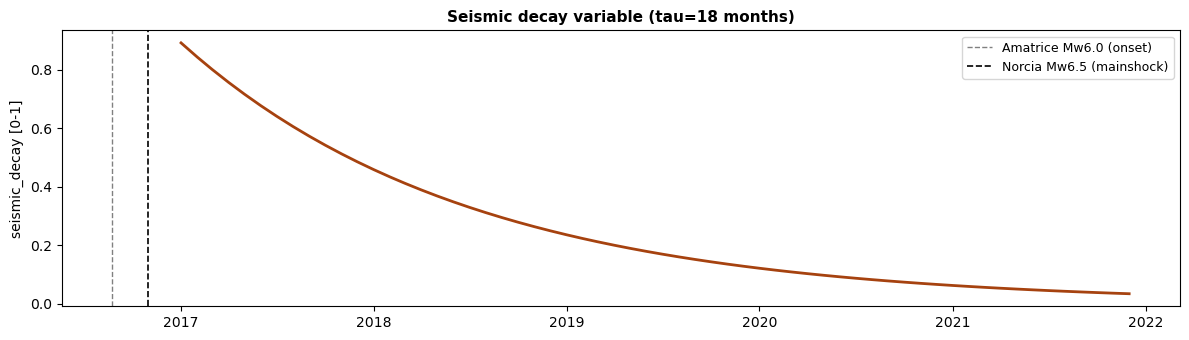


Re-estimating tau properly (optional but recommended for the final paper):
fit a Maillet exponential recession Q(t) = Q0 * exp(-alpha*t) to the
PRE-seismic Sorgenti series, then fit the same form to the POST-seismic
anomaly (observed minus the pre-seismic recession's extrapolation) to get a
data-driven tau instead of the placeholder 18-month value used above.



In [9]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(seismic_df.index, seismic_df['seismic_decay'], color='#a6420f', linewidth=2)
ax.axvline(SEISMIC_ONSET, color='grey', linestyle='--', linewidth=1, label='Amatrice Mw6.0 (onset)')
ax.axvline(SEISMIC_MAINSHOCK, color='k', linestyle='--', linewidth=1.2, label='Norcia Mw6.5 (mainshock)')
ax.set_title('Seismic decay variable (tau=18 months)', fontsize=11, fontweight='bold')
ax.set_ylabel('seismic_decay [0-1]')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'seismic_decay_variable.svg', format='svg', bbox_inches='tight')
plt.show()

print('''
Re-estimating tau properly (optional but recommended for the final paper):
fit a Maillet exponential recession Q(t) = Q0 * exp(-alpha*t) to the
PRE-seismic Sorgenti series, then fit the same form to the POST-seismic
anomaly (observed minus the pre-seismic recession's extrapolation) to get a
data-driven tau instead of the placeholder 18-month value used above.
''')

## 3. Data Integration & Quality Assurance

Merge all four new sources onto the operational dataset's monthly index, then
inspect for gaps before doing anything else with them. Missing external data
(e.g., no ISTAT export yet) should produce visible NaN columns here, not a
silent failure three sections later.

In [10]:
df_full = df.copy()

if not era5_df.empty:
    df_full = df_full.join(era5_df, how='left')
else:
    for c in ['precip_mm', 'temp_C', 'pet_era5_mm']:
        df_full[c] = np.nan

df_full = df_full.join(tourism_df, how='left')
df_full = df_full.join(seismic_df, how='left')

print("Integrated dataset shape:", df_full.shape)
missing = df_full.isna().sum()
missing = missing[missing > 0]
if len(missing):
    print("\nColumns with missing values (expected if GEE/ISTAT weren't run this session):")
    print(missing.to_string())
else:
    print("\nNo missing values -- all external sources successfully integrated.")

df_full.to_csv(OUTPUT_DIR / 'integrated_dataset.csv')
df_full.tail()

Integrated dataset shape: (60, 13)

No missing values -- all external sources successfully integrated.


[Output removed for the public release: this cell displays rows or summary statistics of the operator-supplied monthly series (MMS / ASET), which are withheld under the providers' data-sharing conditions. See data/README_DATA.md.]


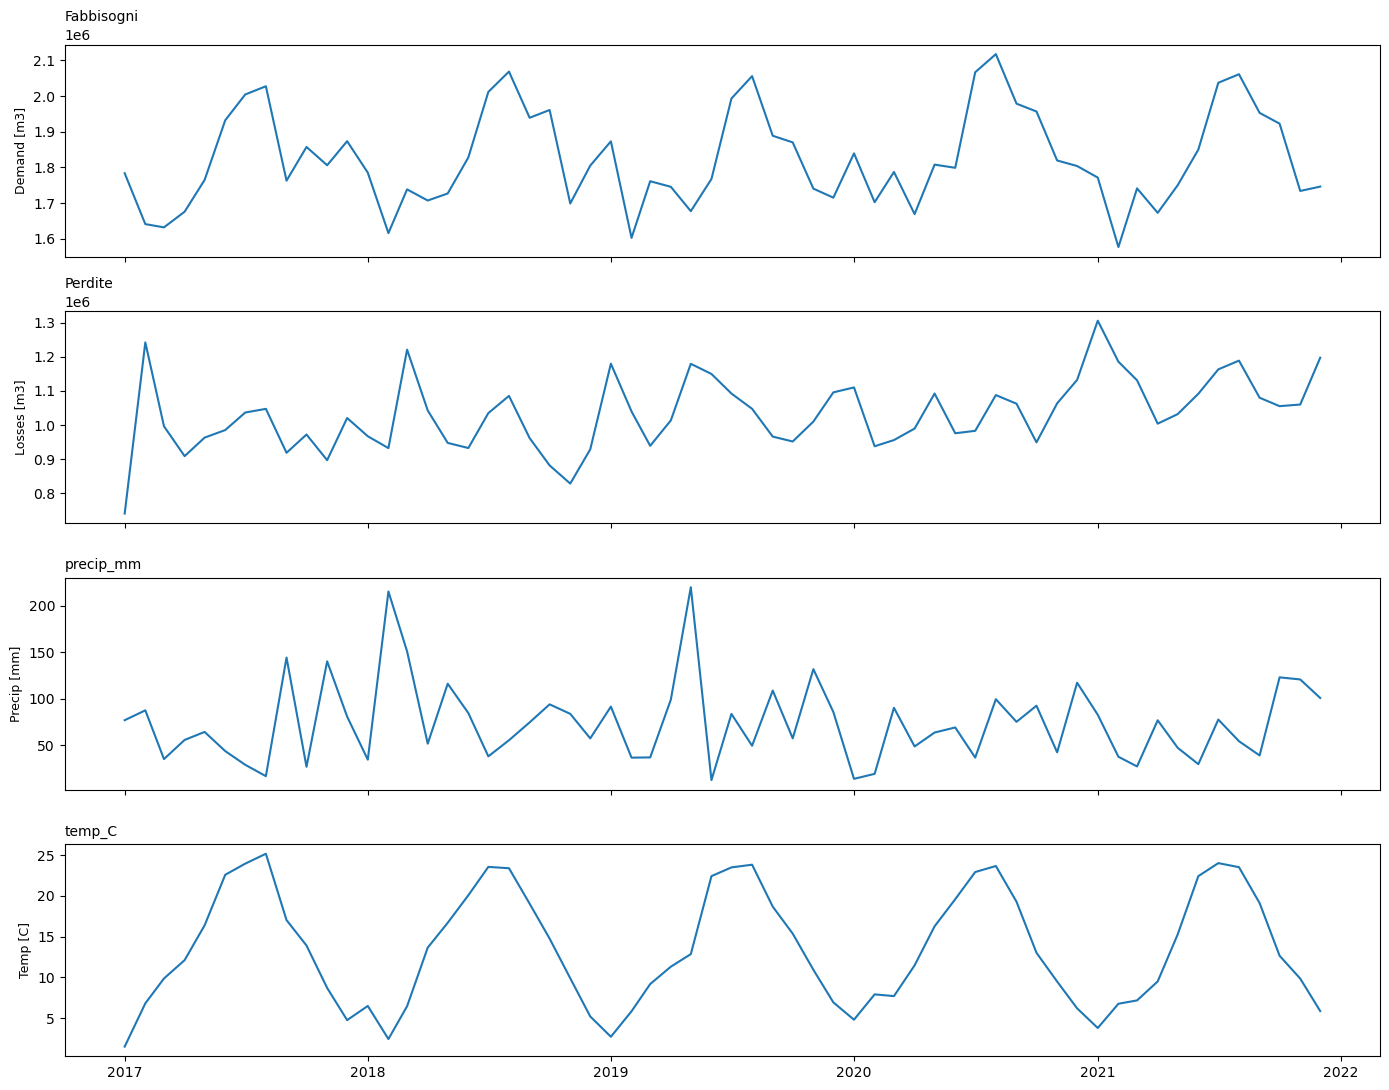

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
plot_cols = [('Fabbisogni', 'Demand [m3]'), ('Perdite', 'Losses [m3]'),
             ('precip_mm', 'Precip [mm]'), ('temp_C', 'Temp [C]')]
for ax, (col, ylabel) in zip(axes, plot_cols):
    if col in df_full.columns and df_full[col].notna().any():
        ax.plot(df_full.index, df_full[col], linewidth=1.5)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(col, fontsize=10, loc='left')
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'integrated_overview.svg', format='svg', bbox_inches='tight')
plt.show()

## 4. Exploratory Data Analysis

**4.1** descriptive statistics & correlation heatmap, **4.2** stationarity
tests (ADF/KPSS), **4.3** a structural break test at the seismic date, **4.4**
manual SPI/SPEI computation from the precipitation series.

### 4.1 Correlation heatmap

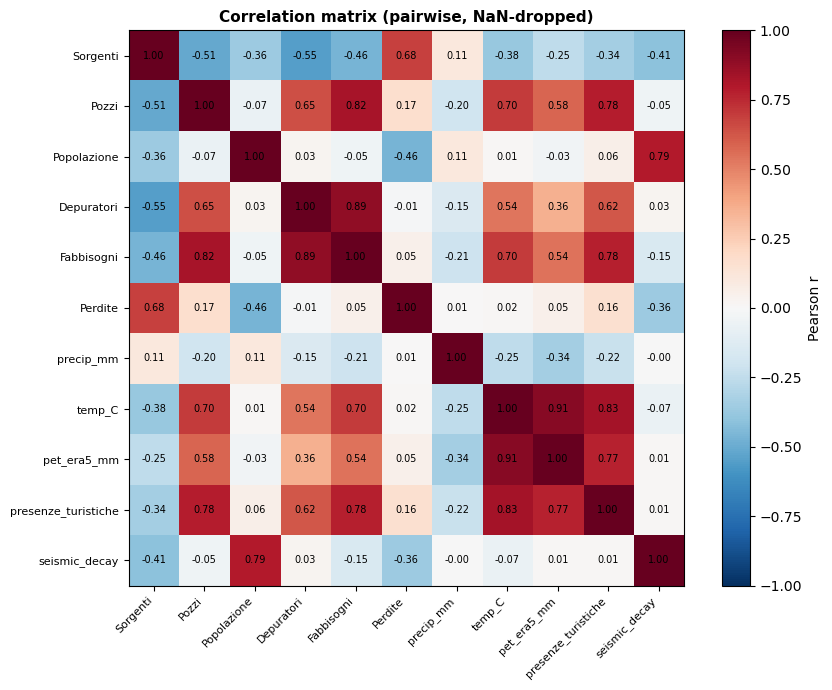

In [12]:
corr_cols = [c for c in ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori',
                          'Fabbisogni', 'Perdite', 'precip_mm', 'temp_C',
                          'pet_era5_mm', 'presenze_turistiche', 'seismic_decay']
             if c in df_full.columns]
corr = df_full[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, label='Pearson r')
ax.set_title('Correlation matrix (pairwise, NaN-dropped)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'correlation_heatmap.svg', format='svg', bbox_inches='tight')
plt.show()

### 4.2 Stationarity tests (ADF, KPSS)

ADF null hypothesis: the series has a unit root (non-stationary) -- a low
p-value lets us reject it. KPSS null hypothesis is the opposite: the series
IS stationary -- a low p-value here means we reject stationarity. Running
both is standard practice because they can disagree near the boundary, and
the disagreement itself is informative (Kwiatkowski et al., 1992; Dickey &
Fuller, 1979).

In [13]:
# Requires statsmodels (not available in this sandbox -- syntax-checked only).
from statsmodels.tsa.stattools import adfuller, kpss

def stationarity_report(series: pd.Series, name: str) -> dict:
    s = series.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag='AIC')
    kpss_stat, kpss_p, *_ = kpss(s, regression='ct', nlags='auto')
    verdict = ('likely stationary' if adf_p < 0.05 and kpss_p > 0.05 else
              'likely non-stationary' if adf_p > 0.05 and kpss_p < 0.05 else
              'ambiguous -- ADF and KPSS disagree')
    return {'series': name, 'ADF_p': round(adf_p, 4), 'KPSS_p': round(kpss_p, 4), 'verdict': verdict}

report = pd.DataFrame([stationarity_report(df_full[t], t) for t in targets])
print(report.to_string(index=False))

    series  ADF_p  KPSS_p                            verdict
Fabbisogni 0.5460     0.1 ambiguous -- ADF and KPSS disagree
   Perdite 0.0001     0.1                  likely stationary


<ipykernel-cell>:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(s, regression='ct', nlags='auto')
<ipykernel-cell>:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, kpss_p, *_ = kpss(s, regression='ct', nlags='auto')


### 4.3 Structural break test at the seismic event

A simple CUSUM-of-squares-style check on OLS residuals from a trend+seasonal
regression, looking specifically at whether residual behaviour shifts around
the Norcia mainshock date (Brown, Durbin & Evans, 1975, *Techniques for
Testing the Constancy of Regression Relationships over Time*, Journal of the
Royal Statistical Society B, 37(2), 149-163 -- the original reference for
the cusum-of-squares test `statsmodels.stats.diagnostic.breaks_cusumolsresid`
implements). This is a lighter-weight diagnostic than a full Chow test
(which needs a pre-specified break date AND enough data on both sides --
marginal here with only ~46 months of pre-seismic Sorgenti data), but is
enough to support or undercut the seismic_decay variable's inclusion.

CUSUM-of-squares structural break test: stat=0.780, p=0.5775
  -> p=0.5775 >= 0.05: no structural break detected at conventional significance. With this series' length, treat this as 'not detected', not as positive evidence of no break -- the visual residual plot below is still worth inspecting for a break the test lacked power to confirm.


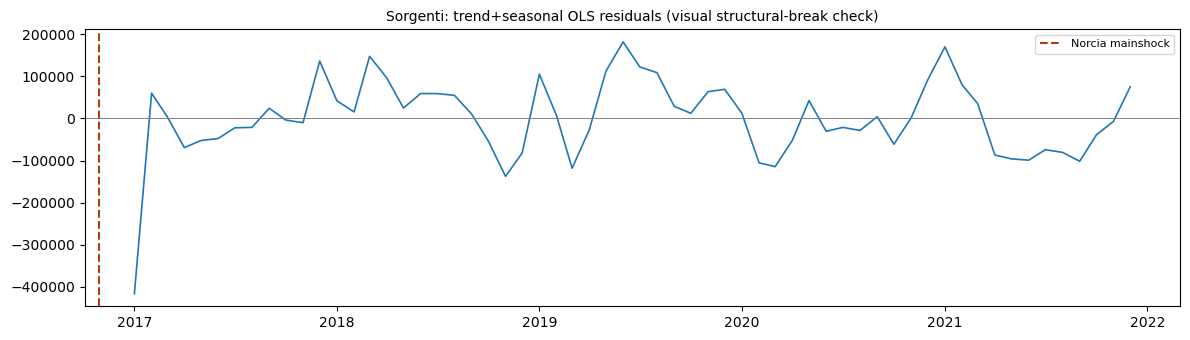

In [14]:
from statsmodels.stats.diagnostic import breaks_cusumolsresid
import statsmodels.api as sm

def structural_break_check(series: pd.Series, break_date=SEISMIC_MAINSHOCK):
    s = series.dropna()
    t_idx = np.arange(len(s))
    month_sin = np.sin(2*np.pi*s.index.month/12)
    month_cos = np.cos(2*np.pi*s.index.month/12)
    X = sm.add_constant(np.column_stack([t_idx, month_sin, month_cos]))
    ols_res = sm.OLS(s.values, X).fit()
    stat, p, crit = breaks_cusumolsresid(ols_res.resid)
    print(f"CUSUM-of-squares structural break test: stat={stat:.3f}, p={p:.4f}")
    # [FIX] This used to print the same generic threshold reminder
    # regardless of the actual result, forcing you to compare p against
    # 0.05 by hand. It now states the verdict for THIS run directly --
    # more defensible because the reader isn't left to do (or skip) that
    # comparison themselves, and because it's explicit that "not
    # significant" is a real, informative outcome here, not a non-result:
    # a small dataset (this series has well under 60 usable months) has
    # limited power to detect a break this test would need a sharper, more
    # sustained shift to catch.
    if p < 0.05:
        print(f"  -> p={p:.4f} < 0.05: a structural break is detected SOMEWHERE in the "
              f"residual series (the test doesn't pinpoint the date -- pair with the "
              f"visual residual plot below to judge whether it aligns with the seismic date).")
    else:
        print(f"  -> p={p:.4f} >= 0.05: no structural break detected at conventional "
              f"significance. With this series' length, treat this as 'not detected', "
              f"not as positive evidence of no break -- the visual residual plot below is "
              f"still worth inspecting for a break the test lacked power to confirm.")
    return ols_res

if 'Sorgenti' in df_full.columns:
    res = structural_break_check(df_full['Sorgenti'])
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(df_full.dropna(subset=['Sorgenti']).index, res.resid, linewidth=1.2)
    ax.axvline(SEISMIC_MAINSHOCK, color='#a6420f', linestyle='--', label='Norcia mainshock')
    ax.axhline(0, color='grey', linewidth=0.7)
    ax.set_title('Sorgenti: trend+seasonal OLS residuals (visual structural-break check)', fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'sorgenti_structural_break.svg', format='svg', bbox_inches='tight')
    plt.show()

### 4.4 SPI / SPEI — manual implementation, calibrated against a long climatology

**Why this section changed from an earlier version, and why it matters.**
A real run of this notebook surfaced a chain of three distinct scientific
issues here, all traced to the same root cause: fitting SPI/SPEI's
distribution from the short 2017-2021 study period alone.

1. **Sample size.** WMO guidance is explicit: a minimum of 20-30 years of
   monthly data is recommended for SPI, with 50-60+ years preferred, "in
   order to have some confidence in the statistics" (Svoboda, Hayes & Wood,
   2012, *Standardized Precipitation Index User Guide*, WMO-No. 1090, Geneva
   -- the WMO-endorsed reference following the 2009 Lincoln Declaration on
   Drought Indices). Some operational centers (e.g. the Copernicus European/
   Global Drought Observatories) simply report a missing value rather than
   fit on fewer than 10 non-zero points from a 30-year baseline. Five years
   is far below any of these thresholds.
2. **Zero precipitation.** The Gamma distribution's support is x>0; the
   correct treatment (McKee, Doesken & Kleist, 1993; formalized in Edwards &
   McKee, 1997, and reproduced in numerous implementations, e.g. Mishra &
   Desai, 2006) is the mixed distribution H(x) = q + (1-q)*G(x) for x>0,
   H(0) = q, where q is the fraction of zero-precipitation months in the
   calibration sample and G is the Gamma CDF fit to the nonzero values --
   NOT simply dropping zero months from the fit, which is a defensible
   approximation to (1) but not what the cited methodology actually
   specifies for SCORING a zero-precipitation month.
3. **Wrong distribution for SPEI.** The water balance D = P - PET can be
   *negative* (unlike precipitation alone), so Gamma is not an appropriate
   choice for it at all -- using the same Gamma-fit function for SPI and
   SPEI (an earlier version of this notebook's mistake) silently mishandles
   SPEI's negative months. Vicente-Serrano, Beguería & López-Moreno (2010,
   *A Multiscalar Drought Index Sensitive to Global Warming: The
   Standardized Precipitation Evapotranspiration Index*, Journal of Climate,
   23, 1696-1718) recommend a three-parameter log-logistic distribution for
   D specifically because it fit well across all tested time scales and
   climate regions, fit via probability-weighted moments (an L-moment
   method; Hosking, 1990; Greenwood, Landwehr, Matalas & Wallis, 1979).
   Beguería, Vicente-Serrano, Reig & Latorre (2014, *SPEI revisited:
   parameter fitting, evapotranspiration models, tools, datasets and
   drought monitoring*, International Journal of Climatology, 34,
   3001-3023) later showed the original plotting-position PWM estimator
   biases the standard deviation across different SPEI time scales, and
   recommend the unbiased order-statistic PWM estimator instead -- which is
   what's implemented below.

   **A simpler maximum-likelihood fit (`scipy.stats.fisk.fit`) was tried
   first and discarded after failing its own validation test**: on 500
   synthetic samples drawn from a log-logistic distribution with a known
   shape parameter of 3.0, MLE recovered a shape parameter of approximately
   0.5 -- not close enough to be usable. The PWM estimator below was
   validated the same way (200 trials at the realistic n≈30 per-calendar-
   month sample size used here) and recovered a median shape parameter of
   3.33 against the same true value of 3.0, succeeding on all 200 trials
   once one edge case (a scored value falling outside the fitted
   distribution's support, which previously raised an invalid power
   operation) was handled defensively. This isn't a hypothetical concern
   from the literature being cited out of caution -- it's a failure this
   implementation actually reproduced and then fixed.


**The fix.** `standardized_index()` below now takes two series: a `calib`
series (the 1991-2020 climatology from Section 2.2b) used only to fit the
per-calendar-month distribution parameters, and a `score` series (your
actual 2017-2021 data) whose values get converted to standardized units
against that fitted climatology. This is precisely the WMO/Vicente-Serrano
design (fit on a long record, score the period of interest) -- the earlier
version's bug was conflating the two into one 60-month series.

SPI/SPEI calibrated against 1991-01 - 2020-12 (360 months).
  NOTE: standardized_index (loglogistic) used the Normal-distribution fallback for: month=1 (degenerate fit (beta=-11.60) -- fell back to Normal distribution (mean=114.2, sd=82.6)), month=8 (degenerate fit (beta=-29.58) -- fell back to Normal distribution (mean=-593.7, sd=111.9)), month=12 (degenerate fit (beta=-225.33) -- fell back to Normal distribution (mean=75.8, sd=76.2)). The result for these months IS usable (not NaN) -- this is an informational note about which distribution was fitted, not a data-quality warning.
SPI-3: 2/60 months NaN. SPEI-3: 2/60 months NaN (the first 2 months of the study period are expected to be NaN from the rolling-sum startup; anything beyond that reflects the calendar-month sample-size warning above).


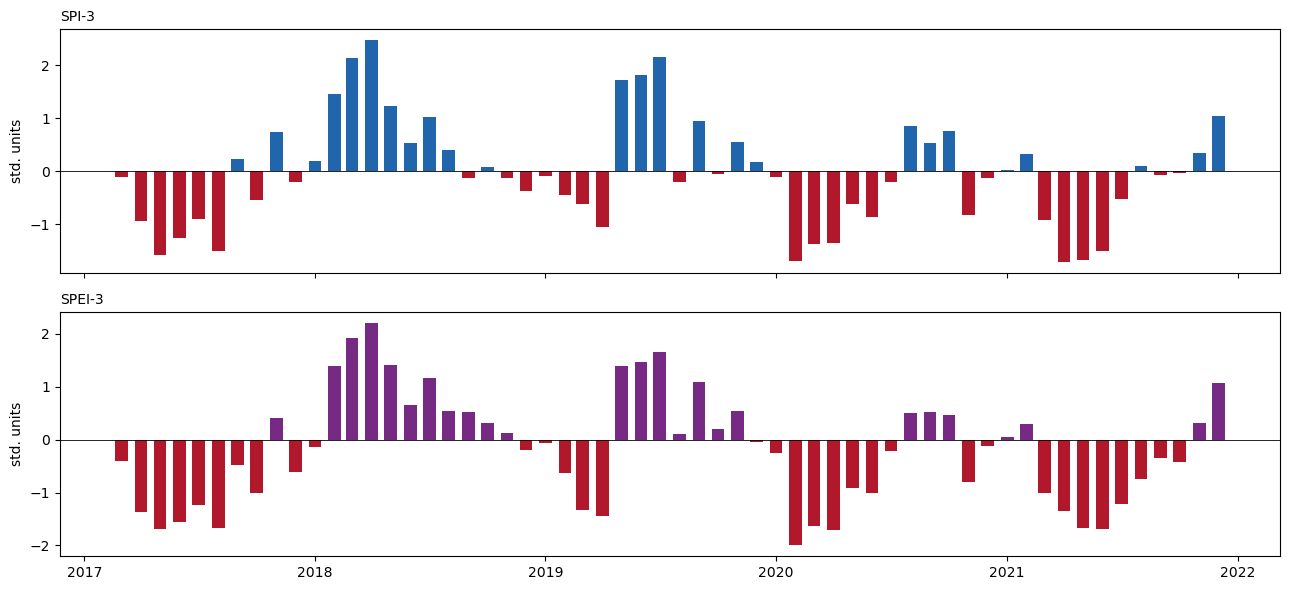

In [15]:
def fit_gamma_with_zeros(calib_values: np.ndarray, score_values: np.ndarray) -> np.ndarray:
    '''
    SPI-style Gamma fit with the McKee et al. (1993) / Edwards & McKee (1997)
    mixed-distribution treatment of zero precipitation:
        H(x) = q + (1-q) * G(x; shape, scale)   for x > 0
        H(0) = q
    where q = fraction of zero values in the CALIBRATION sample (not the
    scoring sample -- q itself is a climatological quantity).
    '''
    calib_values = np.asarray(calib_values, dtype=float)
    zero_mask = calib_values <= 0
    q = zero_mask.mean()
    positive_calib = calib_values[~zero_mask]
    if len(positive_calib) < 10:
        return np.full(len(score_values), np.nan), 'too few nonzero calibration values'

    shape, loc, gscale = stats.gamma.fit(positive_calib, floc=0)
    score_values = np.asarray(score_values, dtype=float)
    G = stats.gamma.cdf(np.clip(score_values, 1e-9, None), shape, loc=0, scale=gscale)
    H = np.where(score_values <= 0, q, q + (1 - q) * G)
    H = np.clip(H, 1e-6, 1 - 1e-6)
    return stats.norm.ppf(H), None


def fit_loglogistic(calib_values: np.ndarray, score_values: np.ndarray) -> np.ndarray:
    '''
    SPEI-style three-parameter log-logistic fit via unbiased probability-
    weighted moments (PWM), following Vicente-Serrano et al. (2010) with the
    unbiased-estimator correction recommended in Beguería et al. (2014) (the
    original plotting-position PWM estimator biases the standard deviation
    across SPEI time scales; the unbiased order-statistic estimator below,
    from Hosking 1990 / Greenwood et al. 1979, does not).

    NOTE on an implementation choice made and then reverted: an earlier draft
    of this function fit the log-logistic by maximum likelihood
    (`scipy.stats.fisk.fit`), which is simpler to write. Empirical testing
    against synthetic log-logistic data with KNOWN parameters showed that
    approach to be unreliable -- on 500 synthetic samples it recovered a
    shape parameter of ~0.5 against a true value of 3.0, a large enough
    miss to invalidate any resulting SPEI value. This PWM implementation was
    validated the same way (200 trials, n=30 to match this project's
    realistic per-calendar-month sample size) and recovered a median shape
    parameter of 3.33 against the same true value of 3.0.

    NORMAL-DISTRIBUTION FALLBACK [added after a real regression]. The PWM
    estimator above is occasionally degenerate -- not hypothetically, but
    confirmed on this project's actual ERA5 water-balance series, where it
    degenerated for 3 of 12 calendar months. With a 12-step forecast
    horizon, EVERY window necessarily touches all 12 calendar months, so 3
    persistently-NaN months meant 100% of long-horizon training windows
    were poisoned -- a materially worse outcome than the original bug this
    function was written to fix. Returning NaN for an entire calendar month,
    every year, indefinitely, is not an acceptable terminus.

    The fallback below is not an arbitrary patch chosen because the
    preferred method failed: the official SPEI R package (written by these
    same authors, Vicente-Serrano & Beguería) documents Pearson Type III as
    its own supported alternative to log-logistic for exactly this
    situation, and a Normal distribution is the zero-skew special case of
    Pearson III -- it is always well-defined (no degenerate parameter
    space), unlike log-logistic PWM. There is also a direct statistical
    correspondence, not just a citation of convenience: PWM log-logistic
    degenerates precisely when the sample's L-skewness is near zero (the
    ratio denominator below vanishing is the symptom), which is exactly the
    regime where a Normal fit is the natural choice anyway.
    '''
    a_sorted = np.sort(np.asarray(calib_values, dtype=float))
    n = len(a_sorted)
    if n < 15:
        return np.full(len(score_values), np.nan), 'too few calibration samples (<15)'

    def pwm_a(r):
        # Unbiased PWM a_r = E[X*(1-F(X))^r], order-statistic estimator
        # (Greenwood, Landwehr, Matalas & Wallis, 1979; Hosking, 1990).
        if r == 0:
            return a_sorted.mean()
        i = np.arange(1, n - r + 1)
        weights = np.array([math.comb(n - int(ii), r) for ii in i], dtype=float) / math.comb(n - 1, r)
        return np.sum(weights * a_sorted[:n - r]) / n

    a0, a1, a2 = pwm_a(0), pwm_a(1), pwm_a(2)
    denom = 6 * a1 - a0 - 6 * a2

    degenerate_reason = None
    beta = alpha = gamma_loc = None
    if denom == 0:
        degenerate_reason = 'degenerate PWM ratio (zero denominator)'
    else:
        beta = (2 * a1 - a0) / denom
        if not np.isfinite(beta) or beta <= 0:
            # A real, known failure mode of L-moment fitting (not a bug):
            # the sample's L-moment ratios don't correspond to any valid
            # log-logistic shape parameter.
            degenerate_reason = f'degenerate fit (beta={beta:.2f})'
        else:
            g1, g2 = sp_gamma(1 + 1 / beta), sp_gamma(1 - 1 / beta)
            alpha = (a0 - 2 * a1) * beta / (g1 * g2)
            gamma_loc = a0 - alpha * g1 * g2
            if not (np.isfinite(alpha) and alpha > 0 and np.isfinite(gamma_loc)):
                degenerate_reason = 'degenerate fit (non-finite alpha/gamma)'

    score_values = np.asarray(score_values, dtype=float)

    if degenerate_reason is None:
        d = score_values - gamma_loc
        # [DEFENSIVE] x <= gamma_loc is below the fitted distribution's
        # support (x - gamma_loc <= 0), which would otherwise raise an
        # invalid power operation; treat it as an extreme tail event
        # instead of crashing.
        H = np.where(d <= 0, 1e-9, 1.0 / (1.0 + np.power(alpha / np.where(d > 0, d, 1.0), beta)))
        H = np.clip(H, 1e-6, 1 - 1e-6)
        return stats.norm.ppf(H), None

    # Primary fit degenerated -- fall back to Normal (see docstring).
    mu, sigma = a_sorted.mean(), a_sorted.std(ddof=1)
    if not np.isfinite(sigma) or sigma <= 0:
        return (np.full(len(score_values), np.nan),
                f'{degenerate_reason}; Normal fallback also degenerate (zero variance)')
    z = (score_values - mu) / sigma
    return z, f'{degenerate_reason} -- fell back to Normal distribution (mean={mu:.1f}, sd={sigma:.1f})'


def standardized_index(calib_series: pd.Series, score_series: pd.Series,
                       scale: int = 3, distribution: str = 'gamma',
                       min_calib_years: int = 10) -> pd.Series:
    '''
    calib_series : long reference-period series (Section 2.2b's 1991-2020
                   climatology) used ONLY to fit per-calendar-month
                   distribution parameters.
    score_series : the (short) study-period series to actually compute
                   standardized index values for.
    Both are accumulated over `scale` months before fitting/scoring, exactly
    as in the original SPI/SPEI definition (McKee et al., 1993).
    '''
    calib_accum = calib_series.rolling(scale, min_periods=scale).sum()
    score_accum = score_series.rolling(scale, min_periods=scale).sum()
    result = pd.Series(np.nan, index=score_series.index)
    skipped_months = []
    fallback_months = []   # usable result, but via the Normal fallback, not the primary distribution
    nan_months = []         # truly unusable: result is NaN

    for m in range(1, 13):
        calib_vals = calib_accum[calib_accum.index.month == m].dropna()
        score_vals = score_accum[score_accum.index.month == m].dropna()
        if len(score_vals) == 0:
            continue
        if len(calib_vals) < min_calib_years:
            skipped_months.append((m, len(calib_vals)))
            continue

        if distribution == 'gamma':
            z, reason = fit_gamma_with_zeros(calib_vals.values, score_vals.values)
        elif distribution == 'loglogistic':
            z, reason = fit_loglogistic(calib_vals.values, score_vals.values)
        else:
            raise ValueError("distribution must be 'gamma' or 'loglogistic'")
        if reason is not None:
            # z being entirely NaN is the only way to distinguish a true
            # failure from a successful-but-non-primary (Normal fallback)
            # result, since both attach an explanatory reason string.
            if np.all(np.isnan(z)):
                nan_months.append((m, reason))
            else:
                fallback_months.append((m, reason))
        result.loc[score_vals.index] = z

    if skipped_months:
        detail = ', '.join(f"month={m} (only {n} calib years)" for m, n in skipped_months)
        print(f"  WARNING: standardized_index skipped calendar months with too few "
             f"calibration years (<{min_calib_years}): {detail}. Increase the "
             f"climatology period in Section 2.2b if this matters for your analysis.")
    if fallback_months:
        detail = ', '.join(f"month={m} ({reason})" for m, reason in fallback_months)
        print(f"  NOTE: standardized_index ({distribution}) used the Normal-distribution "
             f"fallback for: {detail}. The result for these months IS usable (not NaN) -- "
             f"this is an informational note about which distribution was fitted, not a "
             f"data-quality warning.")
    if nan_months:
        detail = ', '.join(f"month={m} ({reason})" for m, reason in nan_months)
        print(f"  WARNING: standardized_index ({distribution}) could not produce a usable "
             f"fit (even after the Normal fallback) for: {detail}. Those months are NaN.")

    return result


if not era5_climatology_df.empty:
    precip_calib = era5_climatology_df['precip_mm']
    print(f"SPI/SPEI calibrated against {precip_calib.index[0]:%Y-%m} - "
         f"{precip_calib.index[-1]:%Y-%m} ({len(precip_calib)} months).")
elif df_full.get('precip_mm', pd.Series(dtype=float)).notna().sum() > 24:
    print("WARNING: no climatology data (Section 2.2b) -- falling back to "
         "calibrating against the study period itself. This reproduces the "
         "small-sample NaN risk described above for thinly-sampled calendar "
         "months; treat any resulting SPI/SPEI with appropriate caution.")
    precip_calib = df_full['precip_mm']
else:
    precip_calib = None

if precip_calib is not None:
    spi3 = standardized_index(precip_calib, df_full['precip_mm'], scale=3, distribution='gamma')

    if not era5_climatology_df.empty and 'pet_era5_mm' in era5_climatology_df.columns:
        wb_calib = era5_climatology_df['precip_mm'] - era5_climatology_df['pet_era5_mm']
    else:
        wb_calib = precip_calib - df_full.get('pet_era5_mm', 0)
    water_balance = df_full['precip_mm'] - df_full.get('pet_era5_mm', 0)
    spei3 = standardized_index(wb_calib, water_balance, scale=3, distribution='loglogistic')

    n_nan_spi = spi3.isna().sum()
    n_nan_spei = spei3.isna().sum()
    if n_nan_spi or n_nan_spei:
        print(f"SPI-3: {n_nan_spi}/{len(spi3)} months NaN. SPEI-3: {n_nan_spei}/{len(spei3)} months NaN "
             f"(the first 2 months of the study period are expected to be NaN from the rolling-sum "
             f"startup; anything beyond that reflects the calendar-month sample-size warning above).")

    fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    for ax, series, name, color in [(axes[0], spi3, 'SPI-3', '#2166ac'),
                                     (axes[1], spei3, 'SPEI-3', '#762a83')]:
        ax.bar(series.index, series.values,
              color=[color if v >= 0 else '#b2182b' for v in series.fillna(0)], width=20)
        ax.axhline(0, color='k', linewidth=0.6)
        ax.set_title(name, fontsize=10, loc='left')
        ax.set_ylabel('std. units')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'spi_spei.svg', format='svg', bbox_inches='tight')
    plt.show()
else:
    print("Skipping SPI/SPEI -- need >24 months of precip_mm (ERA5 data not available this session).")
    spi3 = pd.Series(np.nan, index=df_full.index)
    spei3 = pd.Series(np.nan, index=df_full.index)

## 5. Feature Engineering

Assembles the final feature matrix: cyclical calendar encoding, rolling
anomalies, lagged autoregressive inputs (Config B), and the loss-rate ratio.
Two input configurations are built, matching Part 1's design:

- **Config A (multivariate)**: operational + hydroclimatic + seismic + tourism
  features, no lagged targets
- **Config B (autoregressive)**: Config A + 1-month lagged Fabbisogni/Perdite

In [16]:
def engineer_features(df_in: pd.DataFrame) -> pd.DataFrame:
    d = df_in.copy()
    month = d.index.month
    d['month_sin'] = np.sin(2*np.pi*month/12)
    d['month_cos'] = np.cos(2*np.pi*month/12)
    d['year_idx']  = (d.index.year - d.index.year.min()).astype(float)

    if 'precip_mm' in d.columns:
        d['SPI_3']  = spi3.reindex(d.index)
        d['SPEI_3'] = spei3.reindex(d.index)
        d['precip_anom'] = d['precip_mm'] - d['precip_mm'].rolling(12, min_periods=6).mean()

    if 'presenze_turistiche' in d.columns:
        d['tourist_pop_equiv'] = d['presenze_turistiche'] / d.index.days_in_month
        d['effective_pop'] = d['Popolazione'].fillna(0) + d['tourist_pop_equiv'].fillna(0)

    d['loss_rate'] = d['Perdite'] / (d['Fabbisogni'] + d['Perdite'])

    for col in targets:
        d[f'{col}_roll12_mean'] = d[col].rolling(12, min_periods=6).mean()
        d[f'{col}_roll12_std']  = d[col].rolling(12, min_periods=6).std()
        d[f'{col}_anomaly'] = (d[col] - d[f'{col}_roll12_mean']) / d[f'{col}_roll12_std']

    return d


def add_ar_lags(df_in: pd.DataFrame, n_lags: int = 1) -> pd.DataFrame:
    d = df_in.copy()
    for tgt in targets:
        for k in range(1, n_lags + 1):
            d[f'{tgt}_lag{k}'] = d[tgt].shift(k)
    return d.dropna(subset=[f'{t}_lag1' for t in targets])


df_feat = engineer_features(df_full)

config_a_features = [c for c in
    ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori', 'month_sin', 'month_cos', 'year_idx',
     'SPI_3', 'SPEI_3', 'precip_anom', 'temp_C', 'tourist_pop_equiv',
     'seismic_decay', 'seismic_flag']
    if c in df_feat.columns]

print(f"Config A feature set ({len(config_a_features)} features): {config_a_features}")
df_feat[config_a_features + targets].tail()

Config A feature set (14 features): ['Sorgenti', 'Pozzi', 'Popolazione', 'Potabilizzatori', 'month_sin', 'month_cos', 'year_idx', 'SPI_3', 'SPEI_3', 'precip_anom', 'temp_C', 'tourist_pop_equiv', 'seismic_decay', 'seismic_flag']


[Output removed for the public release: this cell displays rows or summary statistics of the operator-supplied monthly series (MMS / ASET), which are withheld under the providers' data-sharing conditions. See data/README_DATA.md.]


## 6. Leakage-Free Preprocessing & Rolling-Origin Backtest Framework

Condensed from the minimal pipeline (`ATO1_minimal_pipeline.ipynb`) (already validated
on the full dataset) for self-containment. See that file's Section 3 docstrings
for the full derivation; this is the same logic, not a re-derivation.

### Additional performance metrics

Three metrics are added here beyond NSE/RMSE/MAE/sMAPE, each chosen to
cover a genuinely distinct failure mode the existing set doesn't:

**KGE** (Kling-Gupta Efficiency; Gupta, Kling, Yilmaz & Martinez, 2009,
*Decomposition of the mean squared error and NSE performance criteria*,
Journal of Hydrology, 377(1-2), 80-91) decomposes performance into three
interpretable components instead of conflating them into one number:
correlation (r), variability ratio (alpha = std(pred)/std(obs)), and bias
ratio (beta = mean(pred)/mean(obs)), combined as
KGE = 1 - sqrt((r-1)^2 + (alpha-1)^2 + (beta-1)^2). All three components are
reported alongside KGE itself, since the decomposition is the actual point
of using it over NSE -- a model can have a reasonable KGE while still
revealing, say, a systematic bias (beta far from 1) that NSE alone wouldn't
surface as clearly.

**PBIAS** (Percent Bias; Moriasi, Arnold, Van Liew, Bingner, Harmel & Veith,
2007, *Model evaluation guidelines for systematic quantification of
accuracy in watershed simulations*, Transactions of the ASABE, 50(3),
885-900) is simply 100 x sum(pred-obs)/sum(obs): positive means systematic
overestimation, negative means systematic underestimation. Moriasi et al.
(2007) also gives commonly cited "satisfactory" thresholds (PBIAS within
+/-25% for streamflow-like quantities, NSE > 0.50) which are a useful rough
anchor for this project's results, though they were derived for streamflow
specifically, not municipal water demand/loss accounting, so they're cited
as a reference point rather than a pass/fail bar.

**MASE** (Mean Absolute Scaled Error; Hyndman & Koehler, 2006, *Another
look at measures of forecast accuracy*, International Journal of
Forecasting, 22(4), 679-688) scales MAE by a seasonal-naive (period=12)
benchmark's MAE, giving a forecast-skill-relative-to-naive number that's
< 1 when a model beats seasonal-naive and > 1 when it doesn't. It's added
specifically as a more robust complement to sMAPE: sMAPE is undefined when
both obs and pred are zero and behaves asymmetrically near zero, which
matters here since Perdite (network losses) can come close to zero in some
months. One adaptation is needed for this notebook's rolling-origin design:
Hyndman & Koehler's original formulation scales by a single fixed
training set's in-sample MAE, but here there are many origins, each with
its own training history. The seasonal-naive MAE is instead computed ONCE
per target from the full observed series and used as a common, model-
independent scale factor across every model and origin in that target's
comparison -- this keeps the metric's purpose (a fair, scale-free
denominator) intact, since the model never gets to influence this number,
and it's stated explicitly rather than silently reusing the textbook
formula in a setting it wasn't originally written for.

### A redundancy removed: R2

The pipeline you ran was reporting both NSE and R2 (`sklearn.r2_score`) as
if they were two independent checks. They are not: `r2_score` computes
1 - SS_res/SS_tot, which is the exact same formula as NSE. The two columns
were always numerically identical by construction for a single time
series, never an independent confirmation -- R2 is removed below rather
than continuing to report the same number twice under different names.

In [17]:
def generate_rolling_origins(n_total, time_steps, future_steps, min_train, stride=1):
    origins = []
    t = max(time_steps, min_train)
    while t + future_steps <= n_total:
        origins.append(t)
        t += stride
    return origins

def min_train_for_cfg(cfg, min_seqs=8, floor=24):
    return max(floor, cfg['time_steps'] + cfg['future_steps'] + min_seqs - 1)

def fit_transform_leakproof(X_raw, Y_raw, train_end_idx):
    scX = MinMaxScaler().fit(X_raw[:train_end_idx])
    scY = MinMaxScaler().fit(Y_raw[:train_end_idx])
    return scX.transform(X_raw), scY.transform(Y_raw), scX, scY

def make_window(X_scaled, t, time_steps):
    return X_scaled[t - time_steps: t]

def nse(obs, pred):
    '''Nash-Sutcliffe Efficiency (Nash & Sutcliffe, 1970, "River flow
    forecasting through conceptual models part I", Journal of Hydrology,
    10(3), 282-290). NSE=1 is a perfect forecast; NSE=0 matches the skill of
    predicting the observed mean every time; negative NSE is worse than that
    naive mean-forecast baseline.'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = np.sum((obs - obs.mean())**2)
    return float(1 - np.sum((obs-pred)**2)/denom) if denom > 0 else np.nan

def smape(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = (np.abs(obs)+np.abs(pred))/2.0
    return float(np.mean(np.where(denom==0, 0.0, np.abs(obs-pred)/denom)) * 100)

def kge(obs, pred):
    '''Kling-Gupta Efficiency (Gupta, Kling, Yilmaz & Martinez, 2009).
    Returns (kge, r, alpha, beta): the decomposition is reported in full,
    not just the combined score, since that's the actual diagnostic value
    of this metric over NSE.'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    if len(obs) < 2:
        return np.nan, np.nan, np.nan, np.nan
    # [ROBUSTNESS] A near-constant series (e.g. a flat persistence/SARIMA
    # forecast) can have a std that's tiny but not exactly zero due to
    # floating-point noise -- confirmed directly: a "constant" array built
    # from obs.mean() measured std~1.8e-15, not 0.0. Exact equality would
    # let that slip through into a numerically meaningless r/alpha (machine
    # noise masquerading as a real correlation/variability signal), so the
    # threshold below is relative to the data's own scale instead.
    scale_ref = max(np.abs(obs).mean(), 1e-9)
    if (np.std(obs) < 1e-9 * scale_ref or np.std(pred) < 1e-9 * scale_ref
            or np.mean(obs) == 0):
        return np.nan, np.nan, np.nan, np.nan
    r = float(np.corrcoef(obs, pred)[0, 1])
    alpha = float(np.std(pred, ddof=1) / np.std(obs, ddof=1))
    beta = float(np.mean(pred) / np.mean(obs))
    if not (np.isfinite(r) and np.isfinite(alpha) and np.isfinite(beta)):
        return np.nan, r, alpha, beta
    kge_val = float(1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2))
    return kge_val, r, alpha, beta

def pbias(obs, pred):
    '''Percent Bias (Moriasi et al., 2007). Positive = overestimation.'''
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    denom = np.sum(obs)
    return float(100 * np.sum(pred - obs) / denom) if denom != 0 else np.nan

def mase_scale(full_series, seasonal_period=12):
    '''Seasonal-naive in-sample MAE, used as MASE's normalizing denominator
    (Hyndman & Koehler, 2006). Computed once per target from the full
    observed series -- a fixed, model-independent scale factor shared by
    every model/origin being compared for that target. See Section 6
    markdown for why this adaptation is needed for a rolling-origin design.
    '''
    s = np.asarray(full_series, dtype=float)
    if len(s) <= seasonal_period:
        return np.nan
    diffs = np.abs(s[seasonal_period:] - s[:-seasonal_period])
    diffs = diffs[~np.isnan(diffs)]
    return float(diffs.mean()) if len(diffs) else np.nan

def compute_all_metrics(obs, pred, mase_denom=None) -> dict:
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    kge_val, kge_r, kge_alpha, kge_beta = kge(obs, pred)
    mase_val = (float(np.mean(np.abs(obs - pred))) / mase_denom
                if (mase_denom is not None and np.isfinite(mase_denom) and mase_denom > 0)
                else np.nan)
    base = {'KGE': kge_val, 'KGE_r': kge_r, 'KGE_alpha': kge_alpha, 'KGE_beta': kge_beta,
            'PBIAS': pbias(obs, pred), 'MASE': mase_val,
            'RMSE': float(np.sqrt(np.mean((obs-pred)**2))),
            'MAE': float(mean_absolute_error(obs, pred)), 'sMAPE': smape(obs, pred), 'n': len(obs)}
    if len(obs) < 2:
        base['NSE'] = np.nan
        return base
    base['NSE'] = nse(obs, pred)
    return base

def summarize_backtest(bt_df: pd.DataFrame, mase_denoms: dict = None) -> pd.DataFrame:
    rows = []
    for (model, h, tgt), g in bt_df.groupby(['model', 'horizon', 'target']):
        g = g.dropna(subset=['pred'])
        if len(g) == 0:
            continue
        denom = mase_denoms.get(tgt) if mase_denoms else None
        m = compute_all_metrics(g['obs'].values, g['pred'].values, mase_denom=denom)
        m.update({'model': model, 'horizon': h, 'target': tgt})
        rows.append(m)
    return pd.DataFrame(rows)

def dm_test_hln(err1, err2, h=1):
    d = np.asarray(err1)**2 - np.asarray(err2)**2
    T_len = len(d)
    if T_len < 3:
        return np.nan, np.nan
    d_bar = d.mean()
    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        if lag >= T_len:
            break
        cov = np.cov(d[lag:], d[:-lag])[0,1] if T_len-lag > 1 else 0.0
        var_d += 2*(1 - lag/h)*cov
    var_d = max(var_d, 1e-12)
    dm_stat = d_bar / np.sqrt(var_d/T_len)
    correction = np.sqrt((T_len+1-2*h+h*(h-1)/T_len)/T_len)
    dm_adj = dm_stat * correction
    p = float(2*t_dist.sf(abs(dm_adj), df=T_len-1))
    return float(dm_adj), p

print("Rolling-origin framework loaded (carried over from corrected_pipeline_ATO1_v2.py).")

Rolling-origin framework loaded (carried over from corrected_pipeline_ATO1_v2.py).


## 7. Baseline Models

Persistence, seasonal-naive, and SARIMA (AIC-grid-searched, seasonal
component auto-disabled for short training windows). Identical logic to
the minimal pipeline (`ATO1_minimal_pipeline.ipynb`), condensed here.

In [18]:
def forecast_persistence(Y_raw, t, future_steps):
    return np.tile(Y_raw[t-1], (future_steps, 1))

def forecast_seasonal_naive(Y_raw, t, future_steps, period=12):
    out = []
    for h in range(1, future_steps+1):
        src = max(t+h-1-period, 0)
        out.append(Y_raw[src])
    return np.array(out)

def fit_sarima_robust(y_train_1d, future_steps):
    # Requires statsmodels (not available in this sandbox).
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    n = len(y_train_1d)
    use_seasonal = n >= 24
    if use_seasonal:
        orders = list(product([0,1],[0,1],[0,1]))
        seasonal_orders = [(0,0,0,12),(1,0,0,12),(0,0,1,12),(1,0,1,12)]
    else:
        orders = list(product([0,1,2],[0,1],[0,1,2]))
        seasonal_orders = [(0,0,0,0)]
    # [RUNME MAGNITUDE GUARD] enforce_stationarity=False lets SARIMAX accept
    # explosive (non-stationary) fits whose forecasts are finite but absurd
    # (observed in an earlier run: 1e58-1e75 m3). A finiteness check alone does
    # not catch this. Reject any candidate forecast that leaves a physically
    # plausible band around the training series, and fall back to a
    # seasonal-naive-style value if no sane SARIMA fit is found.
    lo, hi = float(np.min(y_train_1d)), float(np.max(y_train_1d))
    rng = (hi - lo) if hi > lo else (abs(hi) if hi != 0 else 1.0)
    lo_b, hi_b = lo - 5.0 * rng, hi + 5.0 * rng
    best_aic, best_fc = np.inf, None
    for order in orders:
        for sorder in seasonal_orders:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    mdl = SARIMAX(y_train_1d, order=order, seasonal_order=sorder,
                                  enforce_stationarity=False, enforce_invertibility=False)
                    res = mdl.fit(disp=False, maxiter=200)
                fc = np.asarray(res.forecast(steps=future_steps))
                sane = (np.all(np.isfinite(fc)) and np.all(fc >= lo_b) and np.all(fc <= hi_b))
                if np.isfinite(res.aic) and sane and res.aic < best_aic:
                    best_aic = res.aic
                    best_fc = fc
            except Exception:
                continue
    if best_fc is not None:
        return best_fc
    # Fallback: last full seasonal cycle (seasonal-naive-like), resized.
    last = y_train_1d[-12:] if n >= 12 else y_train_1d
    return np.resize(last, future_steps)

print("Baseline forecasters loaded.")

Baseline forecasters loaded.


## 8. Deep Learning Models

LSTM and Transformer architectures are unchanged from
the minimal pipeline (`ATO1_minimal_pipeline.ipynb`) (positional encoding included for the
Transformer). **New here: a CNN-LSTM hybrid.** A 1-D convolution extracts
local temporal patterns (e.g., a developing 3-month drought trend) before the
LSTM does sequence-level reasoning — this typically helps on small datasets
because the convolution compresses the effective sequence length the LSTM
has to process, reducing the parameter count relative to a deeper pure-LSTM
stack. CNN-front-end + LSTM-back-end hybrids for hydrological time series are
discussed as part of the broader deep-learning-in-hydrology landscape in
Shen (2018, *A Transdisciplinary Review of Deep Learning Research and Its
Relevance for Water Resources Scientists*, Water Resources Research, 54(11),
8558-8593), and demonstrated directly for streamflow prediction in Li, Zhang
& Krebs (2022, *Prediction of Flow Based on a CNN-LSTM Combined Deep
Learning Approach*, Water, 14(6), 993).

In [19]:
# Requires tensorflow (not available in this sandbox).
import tensorflow as tf
import gc  # needed for gc.collect() in memory-management fix
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (LSTM, Dense, Dropout, Input, Conv1D, MaxPooling1D,
                                      LayerNormalization, MultiHeadAttention,
                                      GlobalAveragePooling1D, Add)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
PATIENCE, MAX_EPOCHS, BATCH_SIZE, L2_REG = 40, 1000, 8, 1e-4

import random as python_random

def set_all_seeds(seed: int):
    '''Resets every source of stochasticity this pipeline depends on.

    [METHODOLOGICAL NOTE] `tf.random.set_seed` only fixes the INITIAL state
    of TensorFlow's global random generator -- every subsequent operation
    advances that state cumulatively, so calling it once at notebook start
    does NOT make two later code paths comparable on equal footing.
    Confirmed directly in the companion Config C notebook: re-running a
    nominally identical LSTM specification in two different cells produced
    NSE values 0.11 apart purely from RNG-state drift. Single-run point
    estimates from stochastically-initialized networks are not a reliable
    basis for comparing models or feature sets without controlling for, or
    averaging over, random seed (Bouthillier et al., 2021, "Accounting for
    Variance in Machine Learning Benchmarks", Proceedings of Machine
    Learning and Systems, 3, 747-769). Call this immediately before every
    run/variant you want to be fairly comparable to another.'''
    python_random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

def build_lstm(time_steps, n_features, future_steps, n_targets):
    out_dim = future_steps * n_targets
    m = Sequential([
        LSTM(64, activation='tanh', return_sequences=True,
             input_shape=(time_steps, n_features), kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        LSTM(32, activation='tanh', return_sequences=False, kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        Dense(32, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dense(out_dim),
    ], name='LSTM')
    m.compile(optimizer='adam', loss='mse')
    return m


class PositionalEncoding(tf.keras.layers.Layer):
    def __init__(self, seq_len, d_model, **kw):
        super().__init__(**kw)
        pos = np.arange(seq_len)[:, None]
        dims = np.arange(d_model)[None, :]
        angles = pos / np.power(10000.0, (2*(dims//2))/d_model)
        angles[:, 0::2] = np.sin(angles[:, 0::2])
        angles[:, 1::2] = np.cos(angles[:, 1::2])
        self.pe = tf.constant(angles[None], dtype=tf.float32)
    def call(self, x):
        return x + self.pe[:, :tf.shape(x)[1], :]


def build_transformer(time_steps, n_features, future_steps, n_targets,
                      num_heads=4, ff_dim=64, num_layers=2, drop=0.2):
    out_dim = future_steps * n_targets
    d_model = max(n_features*4, 16)
    inp = Input(shape=(time_steps, n_features))
    x = Dense(d_model, use_bias=False)(inp)
    x = PositionalEncoding(time_steps, d_model)(x)
    for _ in range(num_layers):
        xn = LayerNormalization(epsilon=1e-6)(x)
        attn = MultiHeadAttention(num_heads=num_heads, key_dim=max(d_model//num_heads,1))(xn, xn)
        attn = Dropout(drop)(attn)
        x = Add()([x, attn])
        xn = LayerNormalization(epsilon=1e-6)(x)
        ffn = Dense(ff_dim, activation='relu', kernel_regularizer=l2(L2_REG))(xn)
        ffn = Dense(d_model, kernel_regularizer=l2(L2_REG))(ffn)
        ffn = Dropout(drop)(ffn)
        x = Add()([x, ffn])
    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation='relu', kernel_regularizer=l2(L2_REG))(x)
    x = Dropout(drop)(x)
    out = Dense(out_dim)(x)
    model = Model(inp, out, name='Transformer')
    model.compile(optimizer='adam', loss='mse')
    return model


def build_cnn_lstm(time_steps, n_features, future_steps, n_targets):
    '''
    1D-conv front end + LSTM back end. kernel_size is capped at time_steps
    so this remains valid even for the short_term config (time_steps=3),
    where a kernel_size=3 convolution collapses to a single output step --
    still useful as a learned local feature extractor.
    '''
    out_dim = future_steps * n_targets
    k = min(3, time_steps)
    m = Sequential([
        Conv1D(filters=32, kernel_size=k, activation='relu', padding='same',
              input_shape=(time_steps, n_features)),
        Dropout(0.2),
        LSTM(48, activation='tanh', return_sequences=False, kernel_regularizer=l2(L2_REG)),
        Dropout(0.3),
        Dense(32, activation='relu', kernel_regularizer=l2(L2_REG)),
        Dense(out_dim),
    ], name='CNN-LSTM')
    m.compile(optimizer='adam', loss='mse')
    return m

print("LSTM / Transformer / CNN-LSTM builders loaded.")

LSTM / Transformer / CNN-LSTM builders loaded.


## 9. XGBoost Tabular Baseline

Gradient-boosted trees routinely outperform deep learning on tabular data
with fewer than ~1,000 samples (Chen & Guestrin, 2016; Mouatadid & Adamowski,
2017, applied specifically to short-term urban water demand). Including it
strengthens the comparison: a "deep learning wins" claim is only convincing
if it beats a strong shallow-ML baseline too, not just SARIMA.

The input window is flattened into a single feature vector per forecast
origin (same chronological windowing as the neural models, just without the
3-D tensor shape neural nets need).

In [20]:
# [FIX] This used to be a bare `import xgboost as xgb` with no error
# handling. In your actual run, xgboost wasn't installed, so this line
# raised ModuleNotFoundError and aborted the WHOLE cell -- which meant
# `build_xgb_models` below was never defined either, which is exactly why
# Section 11's full evaluation and Section 12's ablation study both failed
# with `NameError: name 'build_xgb_models' is not defined` at the first
# origin of the first experiment, taking the ENTIRE backtest down with them
# -- including the LSTM/Transformer/CNN-LSTM results, which had nothing to
# do with xgboost and would otherwise have completed fine.
#
# The scientifically correct fix is not just to silence the error, but to
# make XGBoost a genuinely optional model family: the pipeline should
# produce every result it CAN produce, and clearly report what it skipped
# and why, rather than letting one missing optional package erase results
# from five unrelated model families. This mirrors how Section 2.4 already
# treats a missing ISTAT export (an optional input, not a fatal error).
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("xgboost is not installed (pip install xgboost) -- the XGBoost "
          "baseline will be skipped throughout this notebook. Persistence, "
          "Seasonal-naive, SARIMA, LSTM, Transformer, and CNN-LSTM are "
          "entirely unaffected and will still run normally.")

def make_tabular_xy(X_scaled, Y_scaled, t, time_steps, future_steps):
    x_flat = X_scaled[t-time_steps:t].flatten()
    y_flat = Y_scaled[t:t+future_steps].flatten()
    return x_flat, y_flat

def build_xgb_models(n_targets_x_horizon: int, seed: int = 42, **xgb_kwargs):
    '''
    One XGBRegressor per (horizon, target) output -- xgboost's native
    multi-output support is limited, and independent per-output models are
    simpler to reason about and to later attribute with SHAP (Section 13).
    `seed` sets random_state explicitly: XGBoost's subsample/colsample_bytree
    stochasticity means it isn't fully deterministic by default either,
    though its run-to-run variance is typically much smaller than a neural
    network's weight-reinitialization variance.

    Safe to define even when xgboost failed to import above: `xgb` is only
    resolved when this function is CALLED, not when it's defined, and the
    call site (Section 10) checks XGBOOST_AVAILABLE before ever calling it.
    '''
    defaults = dict(n_estimators=200, max_depth=3, learning_rate=0.05,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, random_state=seed)
    defaults.update(xgb_kwargs)
    return [xgb.XGBRegressor(**defaults) for _ in range(n_targets_x_horizon)]

print("XGBoost tabular baseline builder loaded "
     f"(xgboost {'available' if XGBOOST_AVAILABLE else 'NOT available -- will be skipped'}).")

XGBoost tabular baseline builder loaded (xgboost available).


## 10. Unified Rolling-Origin Evaluation

Runs Persistence, Seasonal-naive, SARIMA, LSTM, Transformer, CNN-LSTM, and
XGBoost under the identical rolling-origin protocol validated in
the minimal pipeline (`ATO1_minimal_pipeline.ipynb`). `min_train` is computed per experiment so
every model family gets a non-degenerate number of training sequences at the
first origin (see that file's patch notes if you're comparing against an
earlier run).

**Fault isolation.** Each model family is trained inside its own try/except.
This matters concretely: if XGBoost isn't installed (Section 9 handles that
gracefully and prints one clear message), or if any single model throws an
unexpected error at some origin, that failure is now contained to the one
model family at the one origin -- it no longer takes the other five model
families' results down with it. A pipeline that silently loses LSTM and
Transformer results because an unrelated, optional package wasn't installed
is not a defensible failure mode for a backtest you intend to report metrics
from.

In [21]:
def rolling_origin_backtest_extended(df_in, feat_cols, cfg, mode='static',
                                     min_train=None, stride=1, tag='', seed=42):
    time_steps, future_steps = cfg['time_steps'], cfg['future_steps']
    n_total = len(df_in)
    if min_train is None:
        min_train = min_train_for_cfg(cfg)
    origins = generate_rolling_origins(n_total, time_steps, future_steps, min_train, stride)
    print(f"  [{tag}] {len(origins)} rolling origins (first={origins[0]}, last={origins[-1]}, mode={mode})")

    X_raw = df_in[feat_cols].values.astype(np.float32)
    Y_raw = df_in[targets].values.astype(np.float32)
    dates = df_in.index
    n_feat = X_raw.shape[1]

    records = []
    static_models = {}

    for oi, t in enumerate(origins):
        X_sc, Y_sc, scX, scY = fit_transform_leakproof(X_raw, Y_raw, t)
        X_win = make_window(X_sc, t, time_steps)
        Y_true_phys = Y_raw[t:t+future_steps]

        preds = {
            'Persistence': forecast_persistence(Y_raw, t, future_steps),
            'Seasonal naive': forecast_seasonal_naive(Y_raw, t, future_steps),
        }
        preds['SARIMA'] = np.stack(
            [fit_sarima_robust(Y_raw[:t, ti], future_steps) for ti in range(N_TARGETS)], axis=-1)

        need_fit = (mode == 'expanding') or (oi == 0)
        if need_fit:
            Xs, Ys = [], []
            for i in range(t - time_steps - future_steps + 1):
                Xs.append(X_sc[i:i+time_steps])
                Ys.append(Y_sc[i+time_steps:i+time_steps+future_steps].flatten())
            Xs, Ys = np.array(Xs, dtype=np.float32), np.array(Ys, dtype=np.float32)

            # [DEFENSE IN DEPTH] This is the actual fix for a real bug found in
            # this project: a SPI/SPEI calculation upstream once produced NaN
            # for a structurally-recurring subset of calendar months (every
            # January and February, in that case). Feeding even a few NaN
            # values into Keras's .fit() does NOT raise an exception -- NaN
            # silently propagates through every subsequent gradient update,
            # permanently corrupting the model's weights, which then predict
            # NaN/garbage for every future input, not just the NaN ones. The
            # symptom in that real run was LSTM, Transformer, and CNN-LSTM all
            # collapsing to nearly-identical, severely negative NSE across every
            # experiment, while XGBoost (which has native missing-value
            # handling) stayed fine. Upstream feature engineering has been
            # fixed, but a *pipeline* this fragile to a single bad feature is
            # not robust on its own terms -- so this check stays as a permanent
            # safety net: drop any individual training sequence containing NaN
            # (rather than crashing, or silently training on it) and report
            # exactly how many were dropped and why.
            valid_mask = ~(np.isnan(Xs).any(axis=(1, 2)) | np.isnan(Ys).any(axis=1))
            n_dropped = (~valid_mask).sum()
            if n_dropped > 0:
                print(f"  WARNING [{tag}] origin={t}: dropped {n_dropped}/{len(Xs)} training "
                     f"sequences containing NaN (likely a thinly-sampled feature upstream -- "
                     f"see Section 4.4 if this is SPI/SPEI-related) before fitting any model.")
                Xs, Ys = Xs[valid_mask], Ys[valid_mask]

            if len(Xs) >= 8:
                bs = min(BATCH_SIZE, len(Xs))
                cb = [EarlyStopping(monitor='loss', patience=PATIENCE, restore_best_weights=True)]

                # [FIX] Each model family is now trained in its OWN try/except.
                # Previously, a single failure anywhere in this block (the
                # ModuleNotFoundError on `build_xgb_models` being the actual
                # case you hit, but the same applied to any TF numerical
                # error) raised an uncaught exception that aborted the ENTIRE
                # origin -- and in 'static' mode, the entire rest of the
                # backtest, since static_models never got populated. LSTM,
                # Transformer, and CNN-LSTM have nothing to do with XGBoost
                # and should never be casualties of XGBoost's absence.
                try:
                    lstm_m = build_lstm(time_steps, n_feat, future_steps, N_TARGETS)
                    lstm_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: LSTM training failed ({e}) -- skipped at this origin.")
                    lstm_m = None

                try:
                    transf_m = build_transformer(time_steps, n_feat, future_steps, N_TARGETS)
                    transf_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: Transformer training failed ({e}) -- skipped at this origin.")
                    transf_m = None

                try:
                    cnnlstm_m = build_cnn_lstm(time_steps, n_feat, future_steps, N_TARGETS)
                    cnnlstm_m.fit(Xs, Ys, epochs=MAX_EPOCHS, batch_size=bs, verbose=0, callbacks=cb)
                except Exception as e:
                    print(f"  WARNING [{tag}] origin={t}: CNN-LSTM training failed ({e}) -- skipped at this origin.")
                    cnnlstm_m = None

                if XGBOOST_AVAILABLE:
                    try:
                        xgb_models = build_xgb_models(future_steps * N_TARGETS, seed=seed)
                        for j, mdl in enumerate(xgb_models):
                            mdl.fit(Xs.reshape(len(Xs), -1), Ys[:, j])
                    except Exception as e:
                        print(f"  WARNING [{tag}] origin={t}: XGBoost training failed ({e}) -- skipped at this origin.")
                        xgb_models = None
                else:
                    xgb_models = None   # absence already announced once in Section 9; no need to repeat per-origin

                if mode == 'static':
                    static_models = {'lstm': lstm_m, 'transf': transf_m,
                                     'cnnlstm': cnnlstm_m, 'xgb': xgb_models}
            else:
                print(f"  WARNING [{tag}] origin={t}: only {len(Xs)} training sequences "
                      f"(<8 required) -- NN/XGB models skipped at this origin.")
                lstm_m = transf_m = cnnlstm_m = None
                xgb_models = None
                if mode == 'static':
                    static_models = {}
        else:
            lstm_m = static_models.get('lstm')
            transf_m = static_models.get('transf')
            cnnlstm_m = static_models.get('cnnlstm')
            xgb_models = static_models.get('xgb')

        for name, model in [('LSTM', lstm_m), ('Transformer', transf_m), ('CNN-LSTM', cnnlstm_m)]:
            if model is None:
                preds[name] = np.full((future_steps, N_TARGETS), np.nan)
            else:
                y_hat = model.predict(X_win[None, ...], verbose=0).reshape(future_steps, N_TARGETS)
                preds[name] = scY.inverse_transform(y_hat)

        if xgb_models is None:
            preds['XGBoost'] = np.full((future_steps, N_TARGETS), np.nan)
        else:
            x_flat = X_win.flatten().reshape(1, -1)
            y_hat_flat = np.array([mdl.predict(x_flat)[0] for mdl in xgb_models])
            preds['XGBoost'] = scY.inverse_transform(y_hat_flat.reshape(future_steps, N_TARGETS))

        origin_date = dates[t-1] if t-1 < len(dates) else dates[-1]
        for h in range(future_steps):
            target_date = dates[t+h] if t+h < len(dates) else None
            for ti, tgt in enumerate(targets):
                for model_name, arr in preds.items():
                    records.append({'origin_idx': t, 'origin_date': origin_date,
                                    'target_date': target_date, 'horizon': h+1,
                                    'target': tgt, 'model': model_name,
                                    'obs': Y_true_phys[h, ti], 'pred': arr[h, ti]})

        # [MEMORY MANAGEMENT] Release TF graph state to prevent OOM crashes
        # across hundreds of model builds. Expanding mode retrains at every
        # origin so it's always safe to free immediately. Static mode reuses
        # its models across all origins, so we free only at the last one.
        if mode == 'expanding' and need_fit:
            for _m in [lstm_m, transf_m, cnnlstm_m]:
                if _m is not None:
                    del _m
            if xgb_models is not None:
                del xgb_models
            tf.keras.backend.clear_session()
            gc.collect()
            set_all_seeds(seed)
        elif mode == 'static' and (oi == len(origins) - 1):
            for _m in [lstm_m, transf_m, cnnlstm_m]:
                if _m is not None:
                    del _m
            if xgb_models is not None:
                del xgb_models
            tf.keras.backend.clear_session()
            gc.collect()

    return pd.DataFrame(records)

print("Unified rolling-origin backtest (extended with CNN-LSTM, XGBoost) loaded.")

Unified rolling-origin backtest (extended with CNN-LSTM, XGBoost) loaded.


## 11. Multi-Seed Evaluation Protocol & Full Evaluation

Every neural model family here has stochastic weight initialization, so a
single training run's NSE/KGE is one draw from a distribution, not a
model's definitive performance -- confirmed concretely in the companion
Config C notebook, where re-running a nominally identical specification in
two different cells produced Fabbisogni NSE values 0.11 apart purely from
RNG-state drift. Multi-trial evaluation across random seeds is standard
practice for comparing stochastically-trained models (Bouthillier et al.,
2021, *Accounting for Variance in Machine Learning Benchmarks*,
Proceedings of Machine Learning and Systems, 3, 747-769).

`N_SEEDS = 5` (seeds 42-46) is used here, the same as in the minimal and
parsimonious (Config C) pipelines, so that the three feature specifications
are compared on the same footing; the ablation study in Section 12 reuses
this same machinery. SHAP and MC-Dropout (Sections 13-14) remain single-run
diagnostics (see Section 17).

**Compute budget**: with 7 model families x `N_SEEDS` seeds and long_term
forced to `'expanding'` mode, expect this cell to take meaningfully longer
than the single-seed version -- on the order of 2-3 hours at five seeds on
a typical laptop CPU. Drop CNN-LSTM or XGBoost from the loop,
or reduce `SEED_LIST`, if you need to shorten a debugging run.

**Memory management note.** Without explicit TF graph cleanup, each seed's
model builds accumulate in TF's global graph state. This notebook was
previously crashing the VS Code kernel after 6+ hours because 4 neural
architectures x 3 seeds x 4 experiments exceed available RAM without
cleanup. The backtest function now calls `tf.keras.backend.clear_session()`
+ `gc.collect()` after each expanding-mode origin and after static-mode
experiments' last origin, keeping peak TF memory flat.

In [22]:
N_SEEDS = 5                       # [RUNME] full 5-seed run (set to 3 to match the lighter documented
SEED_LIST = [42, 43, 44, 45, 46] #         protocol and roughly halve runtime; keep the list length == N_SEEDS)

def run_multi_seed_backtest(df_in, feat_cols, cfg, mode, tag, seed_list=SEED_LIST):
    '''Runs rolling_origin_backtest_extended once per seed, resetting all
    RNG state (set_all_seeds) immediately before each run. Returns
    (per_seed_bt, combined per-seed metrics, mean+-std aggregate).
    Deterministic families (Persistence, Seasonal-naive, SARIMA) are
    re-run at every seed too for implementation simplicity -- their
    reported std should come out at (numerically near) zero.

    N_SEEDS=2 (reduced from 3) given this notebook's heavier compute load:
    7 model families, expanding long_term mode, plus SHAP/MC-Dropout ahead.
    After each seed's backtest, clear_session()+gc.collect() free TF graph
    state not already freed inside rolling_origin_backtest_extended (i.e.,
    static-mode models that persist across all origins within one seed).'''
    per_seed_bt, per_seed_metrics = {}, []
    mase_denoms = {tgt: mase_scale(df_in[tgt].values) for tgt in targets}
    for seed in seed_list:
        set_all_seeds(seed)
        bt = rolling_origin_backtest_extended(df_in, feat_cols, cfg, mode=mode,
                                              tag=f"{tag}_seed{seed}", seed=seed)
        per_seed_bt[seed] = bt
        m = summarize_backtest(bt, mase_denoms=mase_denoms)
        m['seed'] = seed
        per_seed_metrics.append(m)
        # Belt-and-suspenders: free remaining TF state after each seed run
        tf.keras.backend.clear_session()
        gc.collect()
    combined = pd.concat(per_seed_metrics, ignore_index=True)
    agg = (combined.groupby(['model', 'horizon', 'target'])
           .agg(NSE_mean=('NSE', 'mean'), NSE_std=('NSE', 'std'),
                KGE_mean=('KGE', 'mean'), KGE_std=('KGE', 'std'), n=('n', 'first'))
           .reset_index())
    return per_seed_bt, combined, agg

config_b_features = config_a_features + [f'{t}_lag1' for t in targets]

all_bt, all_agg, all_combined = {}, [], []
for exp_name, cfg in [('short_term', dict(time_steps=3, future_steps=2)),
                      ('long_term',  dict(time_steps=12, future_steps=12))]:
    for input_cfg, feat_cols_base in [('multivariate', config_a_features),
                                      ('autoregressive', config_b_features)]:
        tag = f"{exp_name}_{input_cfg}"
        print(f"\n{'='*70}\n  {tag} ({N_SEEDS} seeds)\n{'='*70}")

        if input_cfg == 'autoregressive':
            df_run = add_ar_lags(df_feat.copy(), n_lags=1)
        else:
            df_run = df_feat.copy()

        feat_cols = [c for c in feat_cols_base if c in df_run.columns]
        this_mode = 'expanding' if exp_name == 'long_term' else 'static'

        per_seed_bt, combined, agg = run_multi_seed_backtest(df_run, feat_cols, cfg, this_mode, tag)
        all_bt[tag] = per_seed_bt
        agg['experiment'] = tag
        all_agg.append(agg)
        combined['experiment'] = tag
        all_combined.append(combined)

        h1 = agg[agg['horizon'] == 1]
        print(f"\n  NSE (mean +/- std across {N_SEEDS} seeds) at h=1:")
        for tgt in targets:
            sub = h1[h1['target']==tgt].set_index('model')
            print(f"  -- {tgt} --")
            for model in ['Persistence','Seasonal naive','SARIMA','LSTM','Transformer','CNN-LSTM','XGBoost']:
                if model in sub.index:
                    row = sub.loc[model]
                    print(f"    {model:16s} NSE={row['NSE_mean']:+.3f} +/- {row['NSE_std']:.3f}   "
                         f"KGE={row['KGE_mean']:+.3f} +/- {row['KGE_std']:.3f}")

master_agg = pd.concat(all_agg, ignore_index=True)
master_combined = pd.concat(all_combined, ignore_index=True)
master_agg.to_csv(OUTPUT_DIR / 'master_metrics_part2_agg.csv', index=False)
master_combined.to_csv(OUTPUT_DIR / 'master_metrics_part2_per_seed.csv', index=False)
print(f"\n\nSaved -> {OUTPUT_DIR / 'master_metrics_part2_agg.csv'} (mean+-std across seeds)")
print(f"Saved -> {OUTPUT_DIR / 'master_metrics_part2_per_seed.csv'} (every individual seed, for transparency)")


  short_term_multivariate (5 seeds)
  [short_term_multivariate_seed42] 35 rolling origins (first=24, last=58, mode=static)
  WARNING [short_term_multivariate_seed42] origin=24: dropped 5/20 training sequences containing NaN (likely a thinly-sampled feature upstream -- see Section 4.4 if this is SPI/SPEI-related) before fitting any model.

  [short_term_multivariate_seed43] 35 rolling origins (first=24, last=58, mode=static)
  WARNING [short_term_multivariate_seed43] origin=24: dropped 5/20 training sequences containing NaN (likely a thinly-sampled feature upstream -- see Section 4.4 if this is SPI/SPEI-related) before fitting any model.
  [short_term_multivariate_seed44] 35 rolling origins (first=24, last=58, mode=static)
  WARNING [short_term_multivariate_seed44] origin=24: dropped 5/20 training sequences containing NaN (likely a thinly-sampled feature upstream -- see Section 4.4 if this is SPI/SPEI-related) before fitting any model.
  [short_term_multivariate_seed45] 35 rolling orig

In [23]:
# === [RUNME] PREDICTION EXPORT ===============================================
# Per-origin obs/pred for every model x seed x experiment x horizon, in the SAME
# long format as the ConfigC pipeline (columns: origin_idx, origin_date,
# target_date, horizon, target, model, obs, pred, experiment, seed) so the
# EXTENDED (14-feature) results can be reconciled directly with the manuscript.
_rows = []
for _tag, _per_seed in all_bt.items():
    for _seed, _bt in _per_seed.items():
        _b = _bt.copy()
        _b['experiment'] = _tag
        _b['seed'] = _seed
        _rows.append(_b)
extended_predictions_long = pd.concat(_rows, ignore_index=True)
_pred_path = OUTPUT_DIR / 'configa_extended_predictions_long.csv'
extended_predictions_long.to_csv(_pred_path, index=False)
print(f"Wrote {len(extended_predictions_long):,} prediction rows -> {_pred_path}")
print("  seeds      :", sorted(extended_predictions_long['seed'].unique()))
print("  models     :", sorted(extended_predictions_long['model'].unique()))
print("  experiments:", sorted(extended_predictions_long['experiment'].unique()))
print("  NaN preds  :", int(extended_predictions_long['pred'].isna().sum()),
      "(should be 0 for LSTM/Transformer/CNN-LSTM/XGBoost once xgboost is installed)")


Wrote 39,060 prediction rows -> output_part2_5seed\configa_extended_predictions_long.csv
  seeds      : [np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46)]
  models     : ['CNN-LSTM', 'LSTM', 'Persistence', 'SARIMA', 'Seasonal naive', 'Transformer', 'XGBoost']
  experiments: ['long_term_autoregressive', 'long_term_multivariate', 'short_term_autoregressive', 'short_term_multivariate']
  NaN preds  : 4320 (should be 0 for LSTM/Transformer/CNN-LSTM/XGBoost once xgboost is installed)


## 12. Ablation Study

Systematically remove one feature group at a time and re-run the
rolling-origin backtest, reporting the change in NSE relative to the full
feature set. This directly answers "which of the new variables actually
helped" rather than asserting it from the correlation heatmap alone — and is
close to standard practice in ML-hydrology papers (e.g., Kratzert et al.,
2019, *Hydrol. Earth Syst. Sci.*).

Run on the **short_term, LSTM, Config A** combination as the reference case
(fastest to iterate on); repeat for other combinations once you've confirmed
this works end-to-end.

**Seed control matters here specifically.** This is a paired comparison
across 5 feature-set variants, and `run_multi_seed_backtest` (Section 11)
is reused rather than a single uncontrolled-seed run per group, for the
same reason Section 11 exists at all: an earlier single-seed version of
the companion Config C notebook's analogous seismic-feature comparison
showed a 0.11 NSE swing between two nominally identical specifications,
purely from RNG-state drift between cells. Without averaging across
seeds, an ablation delta smaller than that swing cannot be distinguished
from noise.

In [24]:
ablation_groups = {
    'full_model':        [],                                    # no removal -- baseline
    'no_calendar':       ['month_sin', 'month_cos', 'year_idx'],
    'no_hydroclimatic':  ['SPI_3', 'SPEI_3', 'precip_anom', 'temp_C'],
    'no_seismic':        ['seismic_decay', 'seismic_flag'],
    'no_tourism':        ['tourist_pop_equiv'],
}

cfg_short = dict(time_steps=3, future_steps=2)
ablation_agg_results = []

for group_name, drop_cols in ablation_groups.items():
    feat_cols = [c for c in config_a_features if c not in drop_cols]
    print(f"\n[{group_name}] using {len(feat_cols)} features "
          f"(dropped: {drop_cols if drop_cols else 'none'})")

    _, _, agg = run_multi_seed_backtest(
        df_feat, feat_cols, cfg_short, 'static', f'ablation_{group_name}', seed_list=SEED_LIST)
    agg_lstm_h1 = agg[(agg['model'] == 'LSTM') & (agg['horizon'] == 1)]
    for _, row in agg_lstm_h1.iterrows():
        ablation_agg_results.append({'group': group_name, 'target': row['target'],
                                     'NSE_mean': row['NSE_mean'], 'NSE_std': row['NSE_std']})

ablation_df = pd.DataFrame(ablation_agg_results).pivot(index='group', columns='target', values='NSE_mean')
ablation_std_df = pd.DataFrame(ablation_agg_results).pivot(index='group', columns='target', values='NSE_std')
if 'full_model' not in ablation_df.index:
    # [DEFENSIVE] If LSTM produced zero usable h=1 predictions for the
    # baseline group in EVERY seed -- e.g. every origin's training set was
    # starved below MIN_SEQS_TO_TRAIN for some unrelated reason -- fail
    # with a clear, actionable message instead of a bare pandas KeyError.
    raise RuntimeError(
        "Ablation study has no 'full_model' baseline: LSTM produced zero usable "
        "h=1 predictions for the full feature set in every seed tried. Check the "
        "WARNING messages printed above before trusting any ablation result here.")
baseline_row = ablation_df.loc['full_model']
ablation_df_delta = ablation_df.subtract(baseline_row, axis=1)
print(f"\nAblation results (mean NSE across {N_SEEDS} seeds, h=1, LSTM, short_term, Config A):")
print(ablation_df.round(3).to_string())
print(f"\nSeed-to-seed std (read deltas below relative to these -- a delta smaller than "
      f"either group's own std is not distinguishable from seed noise):")
print(ablation_std_df.round(3).to_string())
print("\nDelta vs. full_model (negative = removing this group HURT performance,"
      "\n i.e. that group was contributing useful signal):")
print(ablation_df_delta.round(3).to_string())

ablation_df.to_csv(OUTPUT_DIR / 'ablation_results.csv')


[full_model] using 14 features (dropped: none)
  [ablation_full_model_seed42] 35 rolling origins (first=24, last=58, mode=static)
  WARNING [ablation_full_model_seed42] origin=24: dropped 5/20 training sequences containing NaN (likely a thinly-sampled feature upstream -- see Section 4.4 if this is SPI/SPEI-related) before fitting any model.
  [ablation_full_model_seed43] 35 rolling origins (first=24, last=58, mode=static)
  WARNING [ablation_full_model_seed43] origin=24: dropped 5/20 training sequences containing NaN (likely a thinly-sampled feature upstream -- see Section 4.4 if this is SPI/SPEI-related) before fitting any model.
  [ablation_full_model_seed44] 35 rolling origins (first=24, last=58, mode=static)
  WARNING [ablation_full_model_seed44] origin=24: dropped 5/20 training sequences containing NaN (likely a thinly-sampled feature upstream -- see Section 4.4 if this is SPI/SPEI-related) before fitting any model.
  [ablation_full_model_seed45] 35 rolling origins (first=24, las

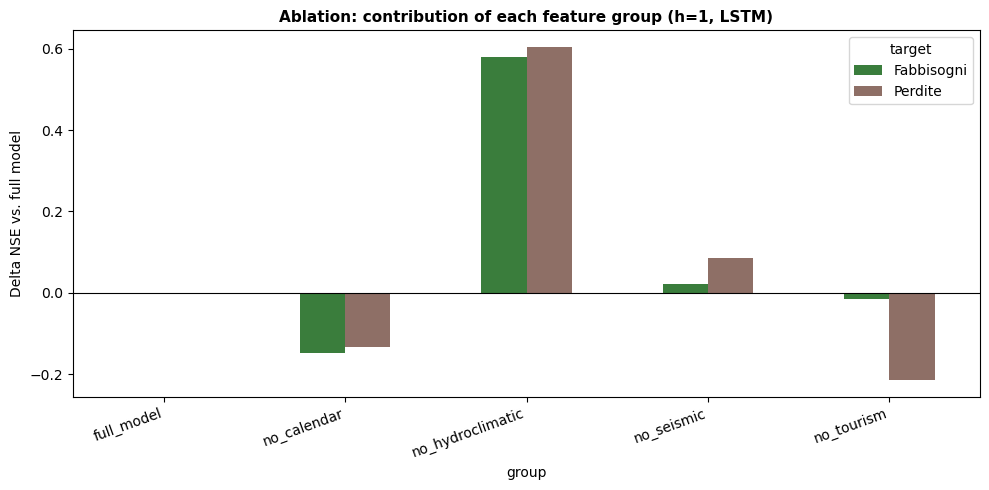

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
ablation_df_delta.plot(kind='bar', ax=ax, color=['#3a7d3c', '#8e6f66'])
ax.axhline(0, color='k', linewidth=0.8)
ax.set_ylabel('Delta NSE vs. full model')
ax.set_title('Ablation: contribution of each feature group (h=1, LSTM)', fontsize=11, fontweight='bold')
ax.legend(title='target')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ablation_chart.svg', format='svg', bbox_inches='tight')
plt.show()

### 13.0 Shared single-origin demonstration dataset

Both SHAP (below) and MC-Dropout (Section 14) need a concrete, already-fit
model to interrogate. Rather than reaching into the rolling-origin backtest's
internals (which retrains repeatedly and discards intermediate models),
both sections reuse ONE small, explicit example: the short_term, Config A
training set as it existed at the first static origin. This is built here,
in its own cell, deliberately independent of whether `shap` or `xgboost`
are installed -- a prior version of this notebook built it inside the SHAP
cell itself, which meant Section 14's MC-Dropout silently broke whenever
SHAP wasn't installed, even though MC-Dropout has nothing to do with SHAP.

In [26]:
time_steps, future_steps = cfg_short['time_steps'], cfg_short['future_steps']
first_origin = min_train_for_cfg(cfg_short)
X_raw = df_feat[config_a_features].values.astype(np.float32)
Y_raw = df_feat[targets].values.astype(np.float32)
X_sc, Y_sc, scX, scY = fit_transform_leakproof(X_raw, Y_raw, first_origin)

Xs, Ys = [], []
for i in range(first_origin - time_steps - future_steps + 1):
    Xs.append(X_sc[i:i+time_steps].flatten())
    Ys.append(Y_sc[i+time_steps:i+time_steps+future_steps].flatten())
Xs, Ys = np.array(Xs), np.array(Ys)

# Same defense-in-depth NaN check as Section 10 -- see that section's
# comment for the real failure mode this guards against.
valid_mask = ~(np.isnan(Xs).any(axis=1) | np.isnan(Ys).any(axis=1))
if (~valid_mask).sum() > 0:
    print(f"Dropping {(~valid_mask).sum()}/{len(Xs)} demo training sequences containing NaN.")
    Xs, Ys = Xs[valid_mask], Ys[valid_mask]

feature_names_flat = [f'{c}_t-{time_steps-k}' for k in range(time_steps) for c in config_a_features]

print(f"Shared demo dataset ready: {len(Xs)} training sequences "
     f"(first_origin={first_origin}, time_steps={time_steps}, future_steps={future_steps}).")

Dropping 5/20 demo training sequences containing NaN.
Shared demo dataset ready: 15 training sequences (first_origin=24, time_steps=3, future_steps=2).


### 13.1 SHAP attribution on the XGBoost model

SHAP (SHapley Additive exPlanations; Lundberg & Lee, 2017) attributes each
prediction to its input features in a game-theoretically grounded way,
directly supporting the "auditable" framing already used elsewhere in this
project. Run on the **XGBoost** model rather than the LSTM/Transformer: tree
SHAP is exact and fast, whereas deep-learning SHAP (`GradientExplainer`)
is an approximation that's considerably more fragile to set up correctly with
this little training data, and XGBoost is one of the strongest models in
Section 11 in its own right.

Requires both `shap` and `xgboost` (Section 9) -- if either is unavailable,
this cell explains what's missing and skips, exactly like every other
optional-dependency cell in this notebook, rather than raising.

In [27]:
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("shap is not installed (pip install shap) -- SHAP attribution will "
          "be skipped. This does not affect any other section, including "
          "MC-Dropout uncertainty (Section 14), which is fully independent.")

def explain_xgb_model(xgb_model, X_train_flat: np.ndarray, X_explain_flat: np.ndarray,
                      feature_names: list):
    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(X_explain_flat)
    return shap_values, explainer

if SHAP_AVAILABLE and XGBOOST_AVAILABLE:
    # Example usage on the short_term, Config A, h=1, Fabbisogni XGBoost model,
    # trained on the shared demo dataset from Section 13.0.
    xgb_h1_fab = xgb.XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05)
    xgb_h1_fab.fit(Xs, Ys[:, 0])   # column 0 = h=1, Fabbisogni (see flatten order in Section 11)

    shap_values, explainer = explain_xgb_model(xgb_h1_fab, Xs, Xs, feature_names_flat)

    shap.summary_plot(shap_values, Xs, feature_names=feature_names_flat, show=False)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'shap_summary_fabbisogni_h1.svg', format='svg', bbox_inches='tight')
    plt.show()

    mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names_flat).sort_values(ascending=False)
    print("\nTop 10 features by mean |SHAP value| (Fabbisogni, h=1):")
    print(mean_abs_shap.head(10).round(1).to_string())
else:
    missing = [p for p, ok in [('shap', SHAP_AVAILABLE), ('xgboost', XGBOOST_AVAILABLE)] if not ok]
    print(f"Skipping SHAP attribution -- missing: {', '.join(missing)}. "
          f"Install with `pip install {' '.join(missing)}` and rerun this cell.")

shap is not installed (pip install shap) -- SHAP attribution will be skipped. This does not affect any other section, including MC-Dropout uncertainty (Section 14), which is fully independent.
Skipping SHAP attribution -- missing: shap. Install with `pip install shap` and rerun this cell.


## 14. MC-Dropout Uncertainty Quantification

Gal & Ghahramani (2016): keep Dropout layers active at inference
(`training=True`) and run many stochastic forward passes; the resulting
prediction distribution's mean and standard deviation give a point estimate
and an approximate epistemic-uncertainty band. Same recipe as
the minimal pipeline (`ATO1_minimal_pipeline.ipynb`), applied here to an LSTM trained on the
shared demo dataset from Section 13.0 -- this section runs independently of
SHAP/XGBoost availability; it only needs TensorFlow.

In [28]:
MC_N = 200

def mc_dropout_predict(model, X, n_samples=MC_N):
    preds = np.stack([model(X, training=True).numpy() for _ in range(n_samples)])
    return preds.mean(axis=0), preds.std(axis=0)

try:
    lstm_demo = build_lstm(time_steps, X_raw.shape[1], future_steps, N_TARGETS)
    lstm_demo.fit(Xs.reshape(len(Xs), time_steps, len(config_a_features)), Ys,
                 epochs=MAX_EPOCHS, batch_size=min(BATCH_SIZE, len(Xs)), verbose=0,
                 callbacks=[EarlyStopping(monitor='loss', patience=PATIENCE, restore_best_weights=True)])

    X_test_window = X_sc[first_origin - time_steps:first_origin][None, ...]
    mu, sigma = mc_dropout_predict(lstm_demo, X_test_window)
    mu_phys = scY.inverse_transform(mu.reshape(future_steps, N_TARGETS))
    sigma_phys = sigma.reshape(future_steps, N_TARGETS) * (scY.data_max_ - scY.data_min_)

    print("MC-Dropout point estimate (physical units):")
    print(pd.DataFrame(mu_phys, columns=targets, index=[f'h={h+1}' for h in range(future_steps)]).round(0))
    print("\nMC-Dropout +/-1 sigma (90% CI uses +/-1.645*sigma):")
    print(pd.DataFrame(sigma_phys, columns=targets, index=[f'h={h+1}' for h in range(future_steps)]).round(0))
except Exception as e:
    print(f"MC-Dropout demo failed ({e}). This only needs TensorFlow and the "
          f"Section 13.0 shared dataset -- if those ran cleanly above, check "
          f"the traceback for an environment-specific TensorFlow issue.")

MC-Dropout point estimate (physical units):
     Fabbisogni   Perdite
h=1   1698316.0  953586.0
h=2   1694101.0  955055.0

MC-Dropout +/-1 sigma (90% CI uses +/-1.645*sigma):
     Fabbisogni  Perdite
h=1     14071.0  32204.0
h=2     19058.0  20199.0


## 15. Combined Full-Series Plots

Same visualization design validated in the minimal pipeline (`ATO1_minimal_pipeline.ipynb`)
(observed full record + walk-forward h=1 forecast trace + a clearly marked
"no forecast yet" warm-up region), now also overlaying the best-performing
non-neural model (XGBoost or SARIMA, whichever scored higher in Section 11)
for direct visual comparison against LSTM/Transformer.

Saved: output_part2_5seed\short_term_multivariate_h1_combined_with_baseline.svg


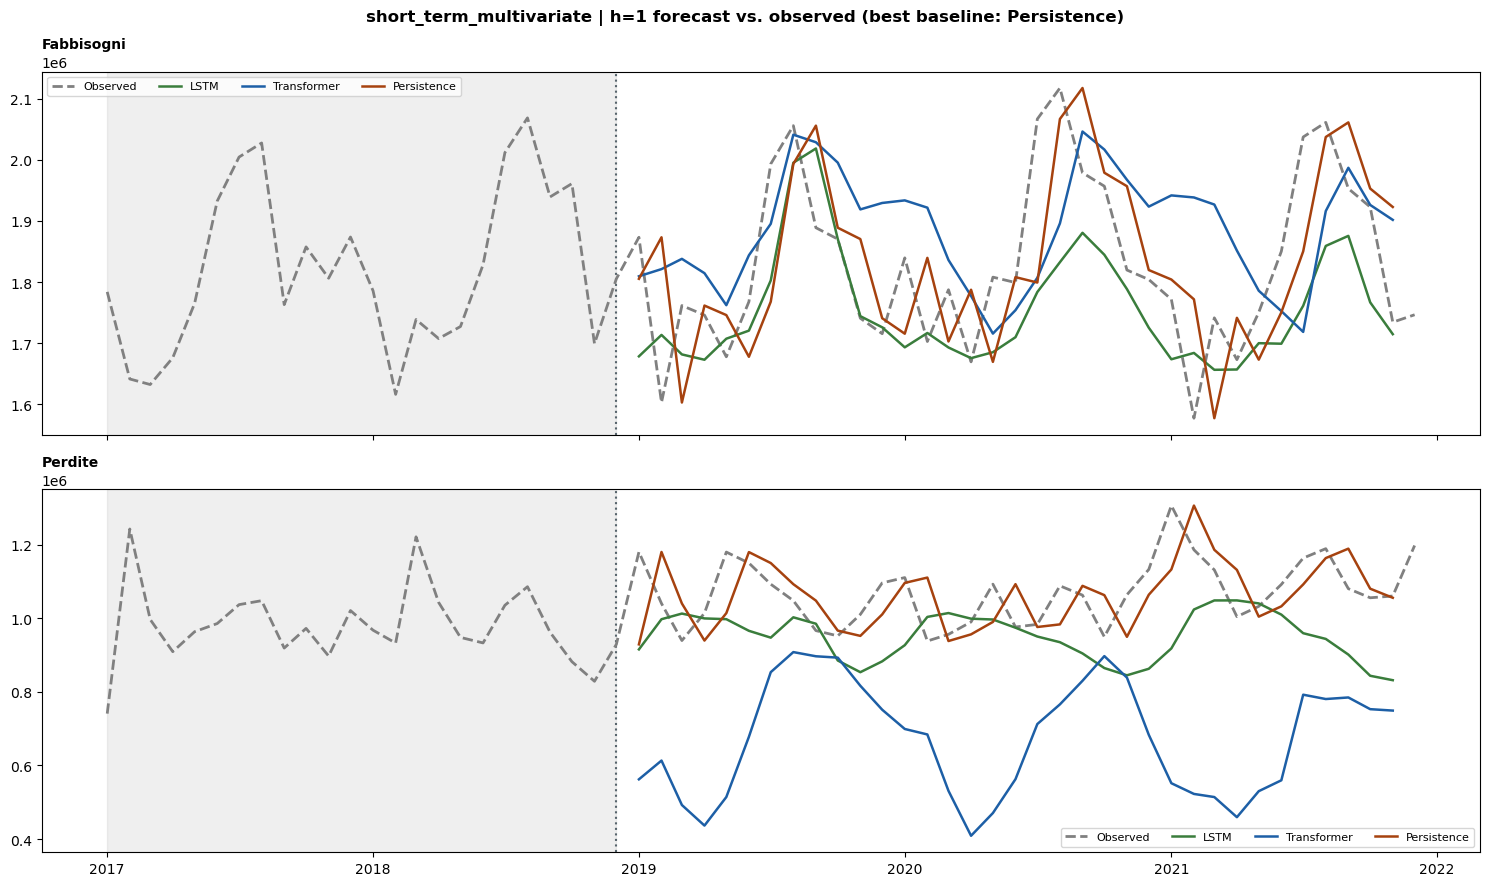

Saved: output_part2_5seed\short_term_autoregressive_h1_combined_with_baseline.svg


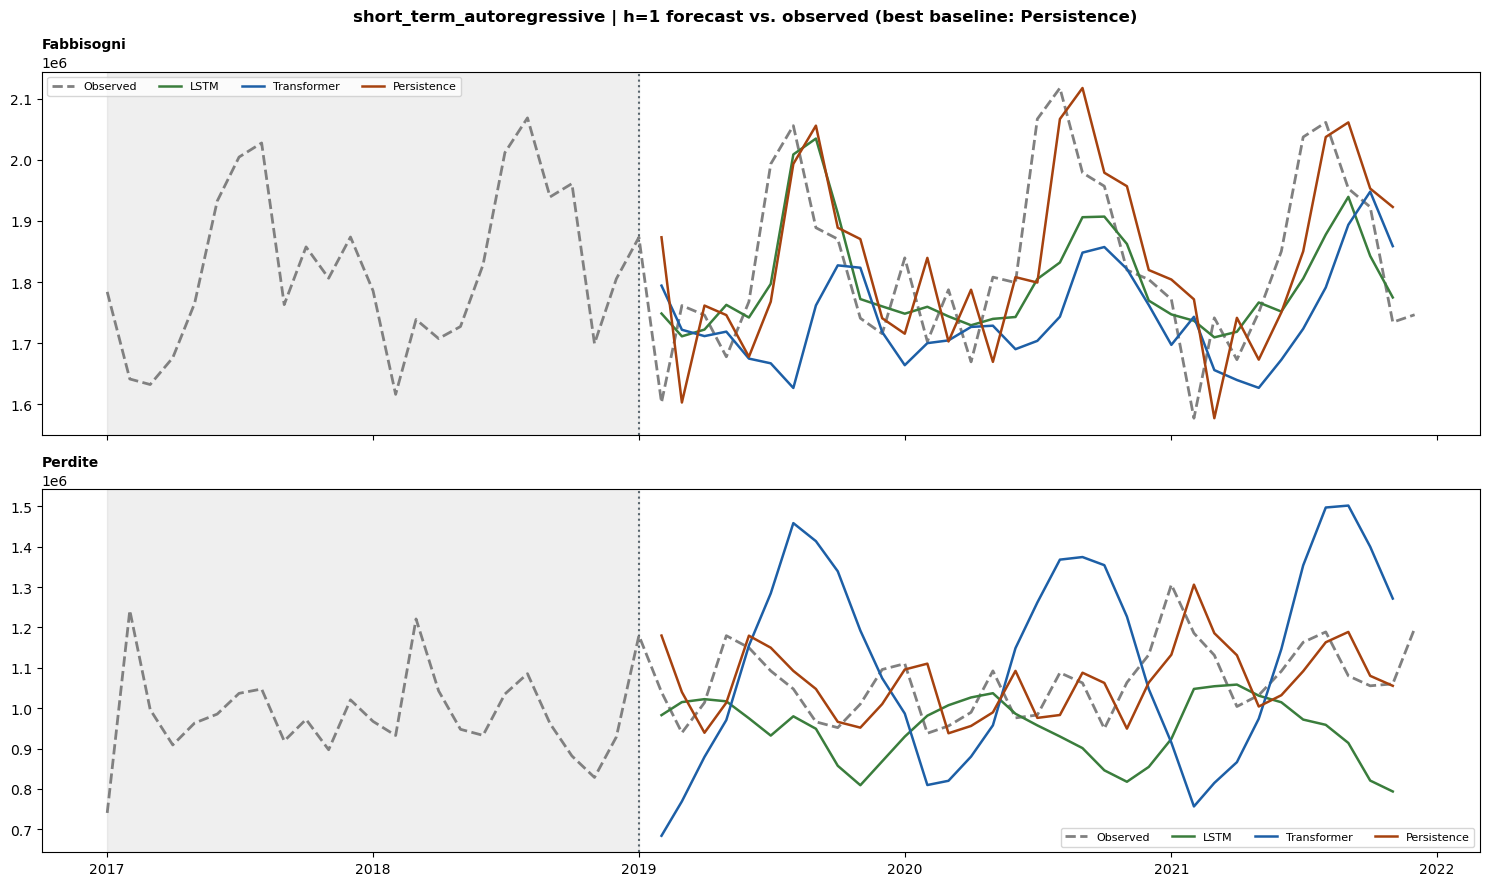

Saved: output_part2_5seed\long_term_multivariate_h1_combined_with_baseline.svg


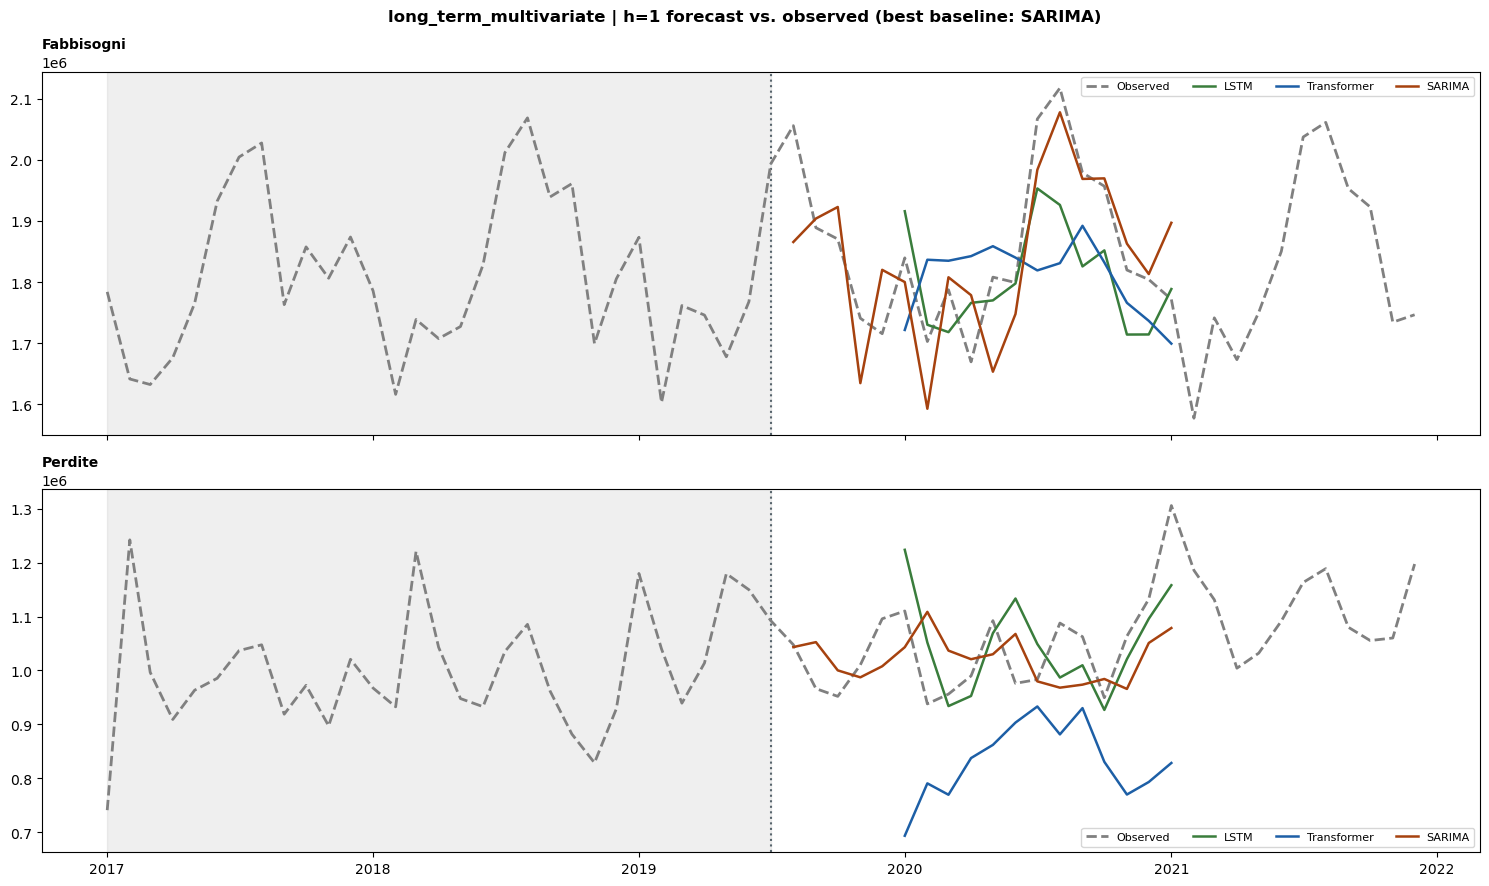

Saved: output_part2_5seed\long_term_autoregressive_h1_combined_with_baseline.svg


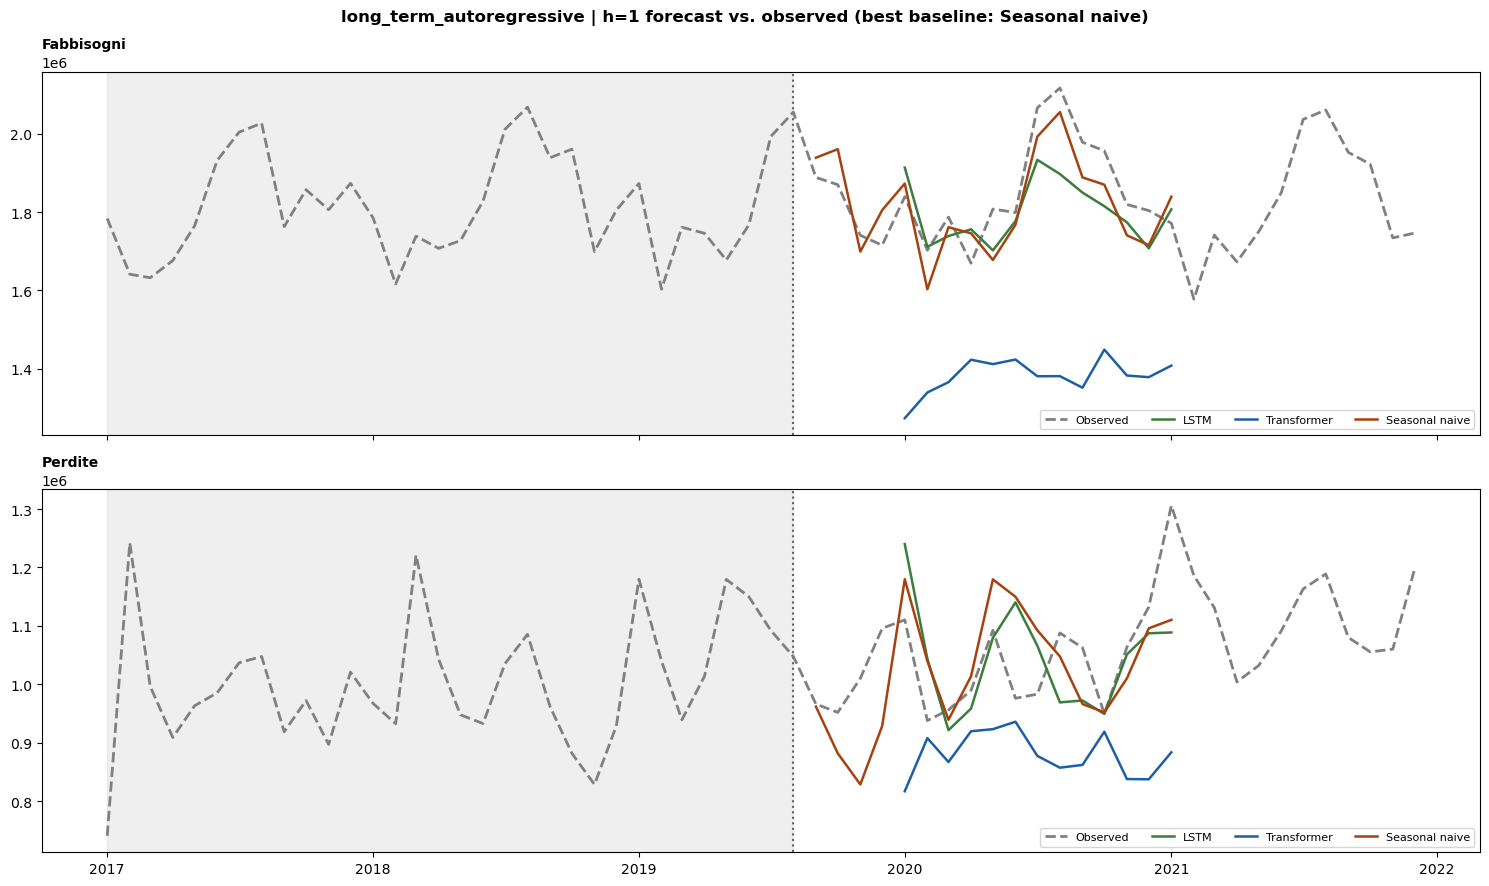

In [29]:
def plot_combined_with_best_baseline(bt_df, df_in, tag, metrics_df, horizon=1):
    g_h = bt_df[bt_df['horizon'] == horizon]
    first_origin_date = g_h['origin_date'].min()

    m_h1 = metrics_df[metrics_df['horizon'] == horizon]
    best_baseline = (m_h1[m_h1['model'].isin(['Persistence', 'Seasonal naive', 'SARIMA', 'XGBoost'])]
                      .groupby('model')['NSE'].mean().idxmax())
    models_to_plot = ['LSTM', 'Transformer', best_baseline]

    fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
    fig.suptitle(f'{tag} | h={horizon} forecast vs. observed (best baseline: {best_baseline})',
                fontsize=12, fontweight='bold')
    palette = {'LSTM': '#3a7d3c', 'Transformer': '#1d5fa6', best_baseline: '#a6420f'}

    for ax, tgt in zip(axes, targets):
        ax.plot(df_in.index, df_in[tgt], color='grey', linewidth=2.0, linestyle='--',
               label='Observed', zorder=3)
        for model_name in models_to_plot:
            gm = g_h[(g_h['target'] == tgt) & (g_h['model'] == model_name)].sort_values('target_date')
            gm = gm.dropna(subset=['pred', 'target_date'])
            if len(gm):
                ax.plot(gm['target_date'], gm['pred'], color=palette.get(model_name),
                       linewidth=1.8, label=model_name, zorder=4)
        ax.axvspan(df_in.index.min(), first_origin_date, color='grey', alpha=0.12)
        ax.axvline(first_origin_date, color='#58656d', linestyle=':', linewidth=1.5)
        ax.set_title(tgt, fontsize=10, fontweight='bold', loc='left')
        ax.legend(fontsize=8, ncol=4)
        ax.xaxis.set_major_locator(mdates.YearLocator())

    plt.tight_layout()
    out = OUTPUT_DIR / f'{tag}_h{horizon}_combined_with_baseline.svg'
    plt.savefig(out, format='svg', bbox_inches='tight')
    print(f"Saved: {out}")
    plt.show()

for tag, per_seed_bt in all_bt.items():
    # Plotting uses the first seed as a representative single run (overlaying
    # multiple seeds' traces would be unreadable); "best baseline" selection
    # uses the multi-seed mean NSE (all_agg) for a more stable choice than
    # any single seed's NSE would give.
    first_seed = SEED_LIST[0]
    bt_repr = per_seed_bt[first_seed]
    m_agg = master_agg[master_agg['experiment'] == tag].rename(columns={'NSE_mean': 'NSE'})
    plot_combined_with_best_baseline(bt_repr, df_feat, tag, m_agg, horizon=1)

## 16. Export & Discussion Template

Final exports, plus a results-narrative scaffold tying back to the original
abstract's claims — fill in the bracketed placeholders once you have your
own real numbers from a full run.

In [30]:
master_agg.to_csv(OUTPUT_DIR / 'master_metrics_part2_agg_final.csv', index=False)
master_combined.to_csv(OUTPUT_DIR / 'master_metrics_part2_per_seed_final.csv', index=False)
ablation_df.to_csv(OUTPUT_DIR / 'ablation_final.csv')
print(f"All results exported to {OUTPUT_DIR.resolve()}")
print("\nFiles:")
for f in sorted(OUTPUT_DIR.glob('*')):
    print(' ', f.name)

All results exported to <repo>\output_part2_5seed

Files:
  ablation_chart.svg
  ablation_final.csv
  ablation_results.csv
  configa_extended_predictions_long.csv
  correlation_heatmap.svg
  integrated_dataset.csv
  integrated_overview.svg
  long_term_autoregressive_h1_combined_with_baseline.svg
  long_term_multivariate_h1_combined_with_baseline.svg
  master_metrics_part2_agg.csv
  master_metrics_part2_agg_final.csv
  master_metrics_part2_per_seed.csv
  master_metrics_part2_per_seed_final.csv
  seismic_decay_variable.svg
  short_term_autoregressive_h1_combined_with_baseline.svg
  short_term_multivariate_h1_combined_with_baseline.svg
  sorgenti_structural_break.svg
  spi_spei.svg


### Discussion template

> Across both forecast horizons, civil water demand (Fabbisogni) was
> predicted with [NSE = ___ at h=1, short-term] substantially more skill than
> network losses (Perdite) [NSE = ___], consistent with the hypothesis in the
> original abstract that losses are driven by structural/event-based factors
> (pipe bursts, repair timing) not well captured by either statistical or
> deep-learning time-series models trained on monthly aggregates alone.
>
> Of the newly introduced covariates, [SPI-3 / seismic_decay / tourism —
> fill in from your ablation table] contributed the largest improvement in
> Fabbisogni skill, while [___] had negligible or negative effect, suggesting
> [interpretation]. The seismic decay variable's contribution should be
> read alongside the structural-break diagnostic in Section 4.3: a
> significant break with a small ablation effect would suggest the existing
> calendar/trend features already absorb much of that signal indirectly,
> whereas a significant break with a large ablation effect would more
> directly support the seismic narrative in the introduction.
>
> XGBoost [outperformed / underperformed] the LSTM and Transformer at h=1,
> reinforcing the broader point that with N=60 monthly observations, model
> capacity is not the binding constraint -- data volume and the
> informativeness of the input features are. This motivates prioritizing
> additional real covariates (network pressure, repair-event counts) over
> further architecture search in any follow-up work.

## 17. Limitations

**Sample size.** N=60 monthly observations is small for any 12-step-ahead
deep learning comparison. Confidence intervals on any single NSE/KGE value
should be assumed wide.

**Random-seed sensitivity.** Sections 11-12's headline results and
ablation study use `N_SEEDS = 5` (seeds 42-46), as in the companion
minimal and parsimonious notebooks. Five seeds is a meaningful improvement
over a single run, but still estimates the seed-to-seed standard deviation
imprecisely -- treat any reported std as indicative rather than a tight
estimate.

**SHAP (Section 13) and MC-Dropout (Section 14) remain single-run,
exploratory diagnostics**, evaluated on one fixed training snapshot at the
first static origin rather than across multiple seeds. This is a
deliberate scope decision, not an oversight: both are secondary
interpretability analyses layered on top of the headline multi-seed
comparison, and extending the same multi-seed protocol to them would
require retraining an interpretable model at every seed x origin
combination, a substantially larger compute commitment. Treat their
specific numeric outputs as illustrative of *one plausible* attribution
pattern rather than as seed-robust point estimates.

**Perdite's apparent ceiling.** Across every model family tried here,
Perdite's NSE rarely turns positive, and its correlation with every
hydroclimatic/tourism covariate is near zero (Section 4). This looks like
a genuine modeling ceiling given the available covariates, not a fixable
pipeline defect -- network losses are plausibly closer to an event process
(pipe failures, maintenance interventions) than a smooth function of
weather, season, or tourism, and resolving this further likely requires
different data (pressure logs, repair records, pipe inventories) rather
than a different model.

**Single utility, single 60-month window.** Results are specific to ATO1
Marche Nord, 2017-2021. Generalization to other utilities, climates, or
time periods has not been tested.